# Proyecto de Minería de Datos - Cine Éxito

## Pregunta objetivo

¿Qué características de las películas se asocian a un mayor éxito en taquilla, de manera que los administradores del cine puedan decidir qué títulos programar para asegurar una alta demanda?

## Fuentes

1. IMDb Dataset
2. TMDB Movies Dataset

## Integrantes

- Santiago Ceballos
- Jhon Harold Ramirez
- Juan Esteban Ceballos
- Erik Torres

Este Notebook corresponde a la etapa de adquisición y preparación inicial de los datos.

## 1. Importación de librerías

Se comienza importando las librerías necesarias donde se descarguen y localicen los datos para leerlos y preparar las fuentes de datos.
Principalmente se usa “Pandas” para manipular los datasets, también se usa “os” el cual ayuda a localizar archivos dentro de las carpetas y “Kagglehub” para obtener las fuentes.
Este Notebook está hecho para ejecutarse desde el principio en Google Colab.


In [1]:

# 1. IMPORTACIÓN DE LIBRERÍAS


import pandas as pd
import numpy as np
import os
import kagglehub

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Descarga y localización de la fuente IMDb

Se intenta obtener IMDb mediante KaggleHub. Si KaggleHub presenta una referencia de versión que ya no existe, el Notebook utiliza como respaldo los archivos oficiales de IMDb (`title.basics.tsv.gz` y `title.ratings.tsv.gz`). De esta forma no se depende de una versión histórica de Kaggle para ejecutar el proyecto en Google Colab.


In [2]:
# ============================================================
# 2. DESCARGA Y LOCALIZACIÓN DE IMDb
# ============================================================

# El proyecto utiliza IMDb como una de sus fuentes principales.
# Se intenta primero reutilizar archivos que ya estén disponibles
# en la caché de Colab/KaggleHub.
#
# Si KaggleHub presenta un error de versión antigua (por ejemplo 404),
# se utiliza como respaldo la fuente oficial de IMDb, que publica
# los mismos archivos TSV de títulos y calificaciones.

NOMBRE_BASICS = "title.basics.tsv"
NOMBRE_RATINGS = "title.ratings.tsv"
HANDLE_IMDB = "ashirwadsangwan/imdb-dataset"

ruta_imdb_basics = None
ruta_imdb_ratings = None

# ------------------------------------------------------------
# 1) Buscar primero archivos ya descargados localmente
# ------------------------------------------------------------

carpetas_busqueda_imdb = [
    "/content",
    os.path.expanduser("~/.cache/kagglehub")
]

for carpeta_base in carpetas_busqueda_imdb:
    if not os.path.isdir(carpeta_base):
        continue

    for raiz, carpetas, archivos in os.walk(carpeta_base):
        if NOMBRE_BASICS in archivos and ruta_imdb_basics is None:
            ruta_imdb_basics = os.path.join(raiz, NOMBRE_BASICS)

        if NOMBRE_RATINGS in archivos and ruta_imdb_ratings is None:
            ruta_imdb_ratings = os.path.join(raiz, NOMBRE_RATINGS)

        if ruta_imdb_basics and ruta_imdb_ratings:
            break

    if ruta_imdb_basics and ruta_imdb_ratings:
        break

# ------------------------------------------------------------
# 2) Si ya existen ambos archivos, reutilizarlos
# ------------------------------------------------------------

if ruta_imdb_basics and ruta_imdb_ratings:
    ruta_imdb = os.path.dirname(ruta_imdb_basics)
    print("IMDb ya está disponible localmente.")
    print("No se realizará ninguna descarga de IMDb.")

else:
    print("No se encontraron ambos archivos IMDb localmente.")
    errores_imdb = []

    # --------------------------------------------------------
    # 3) Intentar KaggleHub sin fijar una versión antigua
    # --------------------------------------------------------
    try:
        print("Intentando obtener IMDb desde KaggleHub...")

        carpeta_imdb_kaggle = "/content/imdb_kaggle"
        os.makedirs(carpeta_imdb_kaggle, exist_ok=True)

        ruta_imdb_descarga = kagglehub.dataset_download(
            HANDLE_IMDB,
            output_dir=carpeta_imdb_kaggle,
            force_download=True
        )

        # Localizar los dos archivos después de la descarga.
        for raiz, carpetas, archivos in os.walk(ruta_imdb_descarga):
            if NOMBRE_BASICS in archivos and ruta_imdb_basics is None:
                ruta_imdb_basics = os.path.join(raiz, NOMBRE_BASICS)

            if NOMBRE_RATINGS in archivos and ruta_imdb_ratings is None:
                ruta_imdb_ratings = os.path.join(raiz, NOMBRE_RATINGS)

            if ruta_imdb_basics and ruta_imdb_ratings:
                break

    except Exception as error_kaggle_imdb:
        errores_imdb.append(
            "KaggleHub -> "
            f"{type(error_kaggle_imdb).__name__}: {error_kaggle_imdb}"
        )
        print("KaggleHub no pudo obtener IMDb.")
        print("Se utilizará la fuente oficial de IMDb como respaldo.")

    # --------------------------------------------------------
    # 4) Respaldo: archivos oficiales publicados por IMDb
    # --------------------------------------------------------
    if not (ruta_imdb_basics and ruta_imdb_ratings):
        print("Descargando los archivos oficiales de IMDb...")

        import urllib.request

        carpeta_imdb_oficial = "/content/imdb_oficial"
        os.makedirs(carpeta_imdb_oficial, exist_ok=True)

        url_basics = "https://datasets.imdbws.com/title.basics.tsv.gz"
        url_ratings = "https://datasets.imdbws.com/title.ratings.tsv.gz"

        archivo_basics_gz = os.path.join(
            carpeta_imdb_oficial,
            "title.basics.tsv.gz"
        )
        archivo_ratings_gz = os.path.join(
            carpeta_imdb_oficial,
            "title.ratings.tsv.gz"
        )

        try:
            if not os.path.isfile(archivo_basics_gz):
                urllib.request.urlretrieve(url_basics, archivo_basics_gz)

            if not os.path.isfile(archivo_ratings_gz):
                urllib.request.urlretrieve(url_ratings, archivo_ratings_gz)

            # Pandas puede leer directamente los archivos comprimidos,
            # por lo que conservamos las rutas .gz como fuente de lectura.
            ruta_imdb_basics = archivo_basics_gz
            ruta_imdb_ratings = archivo_ratings_gz
            ruta_imdb = carpeta_imdb_oficial

            print("Archivos oficiales de IMDb obtenidos correctamente.")

        except Exception as error_oficial_imdb:
            errores_imdb.append(
                "IMDb oficial -> "
                f"{type(error_oficial_imdb).__name__}: {error_oficial_imdb}"
            )

    # --------------------------------------------------------
    # 5) Validación final
    # --------------------------------------------------------
    if not (ruta_imdb_basics and ruta_imdb_ratings):
        detalle = "\n".join(errores_imdb)
        raise RuntimeError(
            "No se pudieron obtener los archivos necesarios de IMDb.\n\n"
            "Se intentó utilizar KaggleHub y, como respaldo, la fuente oficial "
            "de IMDb.\n\n"
            f"Detalles técnicos:\n{detalle}"
        )

print("\nArchivo IMDb Basics encontrado:")
print(ruta_imdb_basics)

print("\nArchivo IMDb Ratings encontrado:")
print(ruta_imdb_ratings)


No se encontraron ambos archivos IMDb localmente.
Intentando obtener IMDb desde KaggleHub...


100%|██████████| 1.73G/1.73G [00:43<00:00, 42.2MB/s]

Extracting files...



Archivo IMDb Basics encontrado:
/content/imdb_kaggle/title.basics.tsv

Archivo IMDb Ratings encontrado:
/content/imdb_kaggle/title.ratings.tsv


## 3. Revisión de la estructura de IMDb
Antes de proceder a cargar los datasets se revisa los encabezados para comprobar que columnas hay disponibles, a su vez se carga una muestra de “title.basics” para poder observar una estructura inicial de los registros.


In [3]:

# 3. REVISIÓN DE LA ESTRUCTURA DE IMDb


imdb_basics_header = pd.read_csv(
    ruta_imdb_basics,
    sep="\t",
    nrows=0
)

imdb_ratings_header = pd.read_csv(
    ruta_imdb_ratings,
    sep="\t",
    nrows=0
)

print("COLUMNAS IMDb - title.basics")
print(imdb_basics_header.columns.tolist())

print("\nCOLUMNAS IMDb - title.ratings")
print(imdb_ratings_header.columns.tolist())

# Muestra inicial de title.basics
imdb_basics_muestra = pd.read_csv(
    ruta_imdb_basics,
    sep="\t",
    nrows=5,
    na_values="\\N"
)

print("\nMuestra inicial de IMDb title.basics:")
display(imdb_basics_muestra)

print("Dimensiones de la muestra:")
print(imdb_basics_muestra.shape)

COLUMNAS IMDb - title.basics
['tconst', 'titleType', 'primaryTitle', 'originalTitle', 'isAdult', 'startYear', 'endYear', 'runtimeMinutes', 'genres']

COLUMNAS IMDb - title.ratings
['tconst', 'averageRating', 'numVotes']

Muestra inicial de IMDb title.basics:


,tconst,titleType,primaryTitle,originalTitle,isAdult,startYear,endYear,runtimeMinutes,genres
0,tt0000001,short,Carmencita,Carmencita,0,1894,NaN,1,"Documentary,Short"
1,tt0000002,short,Le clown et ses chiens,Le clown et ses chiens,0,1892,NaN,5,"Animation,Short"
2,tt0000003,short,Poor Pierrot,Pauvre Pierrot,0,1892,NaN,5,"Animation,Comedy,Romance"
3,tt0000004,short,Un bon bock,Un bon bock,0,1892,NaN,12,"Animation,Short"
4,tt0000005,short,Blacksmith Scene,Blacksmith Scene,0,1893,NaN,1,Short


Dimensiones de la muestra:
(5, 9)


## 4. Carga de la información básica de películas IMDb

Solo se selecciona las columnas necesarias de “title.basics”
El campo “tconst” será un identificador de cada título para luego usarlo al integrar la información de ratings.


In [4]:

# 4. CARGA DE IMDb TITLE.BASICS


columnas_imdb = [
    "tconst",
    "titleType",
    "primaryTitle",
    "startYear",
    "runtimeMinutes",
    "genres"
]

imdb_peliculas = pd.read_csv(
    ruta_imdb_basics,
    sep="\t",
    usecols=columnas_imdb,
    na_values="\\N"
)

print("Datos IMDb title.basics cargados correctamente.")
print("Filas:", len(imdb_peliculas))
print("Columnas:", imdb_peliculas.shape[1])

display(imdb_peliculas.head())

/tmp/ipykernel_702/1599500818.py:13: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  imdb_peliculas = pd.read_csv(


Datos IMDb title.basics cargados correctamente.
Filas: 12965577
Columnas: 6


,tconst,titleType,primaryTitle,startYear,runtimeMinutes,genres
0,tt0000001,short,Carmencita,1894.0,1.0,"Documentary,Short"
1,tt0000002,short,Le clown et ses chiens,1892.0,5.0,"Animation,Short"
2,tt0000003,short,Poor Pierrot,1892.0,5.0,"Animation,Comedy,Romance"
3,tt0000004,short,Un bon bock,1892.0,12.0,"Animation,Short"
4,tt0000005,short,Blacksmith Scene,1893.0,1.0,Short


## 5. Carga de ratings de IMDb

Cargamos el archivo “title.ratings.tsv” en donde están las calificaciones promedio y la cantidad de votos de las películas, luego usamos tconst como identificador para poder relacionar los datos con información básica de las películas

In [5]:

# 5. CARGA DE IMDb TITLE.RATINGS

imdb_ratings = pd.read_csv(
    ruta_imdb_ratings,
    sep="\t",
    usecols=["tconst", "averageRating", "numVotes"],
    na_values="\\N"
)

print("Datos IMDb ratings cargados correctamente.")
print("Filas:", len(imdb_ratings))
print("Columnas:", imdb_ratings.shape[1])

display(imdb_ratings.head())

print("Dimensiones de IMDb Ratings:", imdb_ratings.shape)

Datos IMDb ratings cargados correctamente.
Filas: 1732558
Columnas: 3


,tconst,averageRating,numVotes
0,tt0000001,5.7,2240
1,tt0000002,5.4,330
2,tt0000003,6.4,2410
3,tt0000004,5.0,204
4,tt0000005,6.2,3113


Dimensiones de IMDb Ratings: (1732558, 3)


## 6. Filtrado de películas en IMDb

En IMDb se manejan varios tipos de títulos aunque este proyecto esta enfocado en las peliculas y solo se tienen en cuenta los registros que están como movie en la columna “titleType”

In [6]:
# ============================================================
# 6. FILTRAR SOLAMENTE PELÍCULAS
# ============================================================

imdb_peliculas = imdb_peliculas[
    imdb_peliculas["titleType"] == "movie"
].copy()

print("Cantidad de películas IMDb:", len(imdb_peliculas))

display(imdb_peliculas.head())

Cantidad de películas IMDb: 760989


,tconst,titleType,primaryTitle,startYear,runtimeMinutes,genres
8,tt0000009,movie,Miss Jerry,1894.0,45.0,Romance
144,tt0000147,movie,The Corbett-Fitzsimmons Fight,1897.0,100.0,"Documentary,News,Sport"
498,tt0000502,movie,Bohemios,1905.0,100.0,NaN
570,tt0000574,movie,The Story of the Kelly Gang,1906.0,70.0,"Action,Adventure,Biography"
587,tt0000591,movie,The Prodigal Son,1907.0,90.0,Drama


## 7. Integración de las tablas de IMDb

Se unen title.basics y title.ratings usando la columna tconst que tienen en común. Se hace un inner merge para quedarse solo con las películas que tienen información en las dos tablas y se compara la cantidad de filas antes y después de la unión para llevar un control del proceso

In [7]:
# ============================================================
# 7. CRUCE IMDb BASICS + IMDb RATINGS
# ============================================================

filas_imdb_antes = len(imdb_peliculas)

imdb = pd.merge(
    imdb_peliculas,
    imdb_ratings,
    on="tconst",
    how="inner"
)

filas_imdb_despues = len(imdb)

print("Filas de películas antes:", filas_imdb_antes)
print("Filas después de agregar ratings:", filas_imdb_despues)

print("\nDimensiones del dataset IMDb integrado:", imdb.shape)

display(imdb.head())

Filas de películas antes: 760989
Filas después de agregar ratings: 351819

Dimensiones del dataset IMDb integrado: (351819, 8)


,tconst,titleType,primaryTitle,startYear,runtimeMinutes,genres,averageRating,numVotes
0,tt0000009,movie,Miss Jerry,1894.0,45.0,Romance,5.3,241
1,tt0000147,movie,The Corbett-Fitzsimmons Fight,1897.0,100.0,"Documentary,News,Sport",5.3,618
2,tt0000502,movie,Bohemios,1905.0,100.0,NaN,3.7,27
3,tt0000574,movie,The Story of the Kelly Gang,1906.0,70.0,"Action,Adventure,Biography",6.0,1106
4,tt0000591,movie,The Prodigal Son,1907.0,90.0,Drama,5.1,43


## 8. Descarga y localización de la fuente TMDB

Se intenta obtener el archivo `TMDB_movie_dataset_v11.csv` mediante el identificador actual del dataset en Kaggle, sin fijar una versión numérica. Si KaggleHub no puede descargarlo, se ofrece una carga manual desde Colab para evitar que una versión antigua de Kaggle bloquee todo el Notebook.


In [8]:
# ============================================================
# 8. DESCARGA Y LOCALIZACIÓN DE TMDB
# ============================================================

# Se utiliza el identificador actual del dataset de TMDB.
# No se fija una versión numérica para evitar referencias a versiones
# antiguas que puedan dejar de estar disponibles en Kaggle.

NOMBRE_ARCHIVO_TMDB = "TMDB_movie_dataset_v11.csv"
HANDLE_TMDB = "asaniczka/tmdb-movies-dataset-2023-930k-movies"

ruta_tmdb_archivo = None

# ------------------------------------------------------------
# 1) Buscar primero una copia local existente
# ------------------------------------------------------------

carpetas_tmdb_busqueda = [
    "/content",
    os.path.expanduser("~/.cache/kagglehub")
]

archivos_tmdb_existentes = []

for carpeta_base in carpetas_tmdb_busqueda:
    if not os.path.isdir(carpeta_base):
        continue

    for raiz, carpetas, archivos in os.walk(carpeta_base):
        if NOMBRE_ARCHIVO_TMDB in archivos:
            archivos_tmdb_existentes.append(
                os.path.join(raiz, NOMBRE_ARCHIVO_TMDB)
            )

if archivos_tmdb_existentes:
    ruta_tmdb_archivo = max(
        archivos_tmdb_existentes,
        key=os.path.getmtime
    )
    ruta_tmdb = os.path.dirname(ruta_tmdb_archivo)
    print("TMDB ya está disponible localmente.")
    print("No se realizará ninguna descarga.")

else:
    print("No se encontró TMDB localmente.")
    errores_descarga = []

    # --------------------------------------------------------
    # 2) Intentar KaggleHub usando el handle sin versión fija
    # --------------------------------------------------------
    try:
        print("Intentando descargar TMDB desde KaggleHub...")

        carpeta_tmdb_kaggle = "/content/tmdb_kaggle"
        os.makedirs(carpeta_tmdb_kaggle, exist_ok=True)

        ruta_descarga_tmdb = kagglehub.dataset_download(
            HANDLE_TMDB,
            path=NOMBRE_ARCHIVO_TMDB,
            output_dir=carpeta_tmdb_kaggle,
            force_download=True
        )

        if os.path.isfile(ruta_descarga_tmdb):
            ruta_tmdb_archivo = ruta_descarga_tmdb
        else:
            for raiz, carpetas, archivos in os.walk(ruta_descarga_tmdb):
                if NOMBRE_ARCHIVO_TMDB in archivos:
                    ruta_tmdb_archivo = os.path.join(
                        raiz, NOMBRE_ARCHIVO_TMDB
                    )
                    break

    except Exception as error_descarga:
        errores_descarga.append(
            "KaggleHub -> "
            f"{type(error_descarga).__name__}: {error_descarga}"
        )
        print("KaggleHub no pudo obtener TMDB automáticamente.")

    # --------------------------------------------------------
    # 3) Autenticación opcional: solo una vez
    # --------------------------------------------------------
    if ruta_tmdb_archivo is None:
        print("\nSe intentará autenticar KaggleHub una sola vez.")

        try:
            kagglehub.login()
            print("Autenticación completada.")

            ruta_descarga_tmdb = kagglehub.dataset_download(
                HANDLE_TMDB,
                path=NOMBRE_ARCHIVO_TMDB,
                output_dir="/content/tmdb_kaggle",
                force_download=True
            )

            if os.path.isfile(ruta_descarga_tmdb):
                ruta_tmdb_archivo = ruta_descarga_tmdb
            else:
                for raiz, carpetas, archivos in os.walk(ruta_descarga_tmdb):
                    if NOMBRE_ARCHIVO_TMDB in archivos:
                        ruta_tmdb_archivo = os.path.join(
                            raiz, NOMBRE_ARCHIVO_TMDB
                        )
                        break

        except Exception as error_autenticacion:
            errores_descarga.append(
                "Autenticación -> "
                f"{type(error_autenticacion).__name__}: {error_autenticacion}"
            )

    # --------------------------------------------------------
    # 4) Último respaldo: carga manual desde Colab
    # --------------------------------------------------------
    if ruta_tmdb_archivo is None:
        print("\nNo fue posible obtener TMDB mediante KaggleHub.")
        print("Se abrirá el selector de archivos de Google Colab.")
        print("Selecciona exactamente: TMDB_movie_dataset_v11.csv")

        try:
            from google.colab import files
            archivos_subidos = files.upload()

            if NOMBRE_ARCHIVO_TMDB not in archivos_subidos:
                raise FileNotFoundError(
                    "Debes seleccionar el archivo "
                    "TMDB_movie_dataset_v11.csv."
                )

            ruta_tmdb_archivo = os.path.join(
                "/content",
                NOMBRE_ARCHIVO_TMDB
            )

        except Exception as error_upload:
            errores_descarga.append(
                "Carga manual -> "
                f"{type(error_upload).__name__}: {error_upload}"
            )

    if ruta_tmdb_archivo is None or not os.path.isfile(ruta_tmdb_archivo):
        detalle = "\n".join(errores_descarga)
        raise RuntimeError(
            "No se pudo obtener el archivo TMDB_movie_dataset_v11.csv.\n\n"
            "Se intentó la descarga actual de KaggleHub, una autenticación "
            "única y, finalmente, la carga manual en Colab.\n\n"
            f"Detalles técnicos:\n{detalle}"
        )

    ruta_tmdb = os.path.dirname(ruta_tmdb_archivo)

print("\nRuta de TMDB:")
print(ruta_tmdb)

print("\nArchivo principal de TMDB encontrado:")
print(ruta_tmdb_archivo)


No se encontró TMDB localmente.
Intentando descargar TMDB desde KaggleHub...
Using Colab cache for faster access to the 'tmdb-movies-dataset-2023-930k-movies' dataset.

Ruta de TMDB:
/kaggle/input/tmdb-movies-dataset-2023-930k-movies

Archivo principal de TMDB encontrado:
/kaggle/input/tmdb-movies-dataset-2023-930k-movies/TMDB_movie_dataset_v11.csv


## 9. Revisión de la estructura de TMDB

Antes de cargar los datos que se van a utilizar en el proyecto, se revisan los nombres de las columnas del archivo de TMDB para conocer su estructura.

In [9]:

# 9. REVISIÓN DE LA ESTRUCTURA DE TMDB


tmdb_header = pd.read_csv(
    ruta_tmdb_archivo,
    nrows=0
)

print("COLUMNAS TMDB")
print(tmdb_header.columns.tolist())

# Leer una pequeña muestra para comprobar la estructura.
tmdb_muestra = pd.read_csv(
    ruta_tmdb_archivo,
    nrows=5
)

print("\nMuestra inicial de TMDB:")
display(tmdb_muestra.head())

print("Dimensiones de la muestra:")
print(tmdb_muestra.shape)

COLUMNAS TMDB
['id', 'title', 'vote_average', 'vote_count', 'status', 'release_date', 'revenue', 'runtime', 'adult', 'backdrop_path', 'budget', 'homepage', 'imdb_id', 'original_language', 'original_title', 'overview', 'popularity', 'poster_path', 'tagline', 'genres', 'production_companies', 'production_countries', 'spoken_languages', 'keywords']

Muestra inicial de TMDB:


,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
0,27205,Inception,8.364,34495,Released,2010-07-15,825532764,148,False,/8ZTVqvKDQ8emSGUEMjsS4yHAwrp.jpg,...,Inception,"Cobb, a skilled thief who commits corporate es...",83.952,/oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg,Your mind is the scene of the crime.,"Action, Science Fiction, Adventure","Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili","rescue, mission, dream, airplane, paris, franc..."
1,157336,Interstellar,8.417,32571,Released,2014-11-05,701729206,169,False,/pbrkL804c8yAv3zBZR4QPEafpAR.jpg,...,Interstellar,The adventures of a group of explorers who mak...,140.241,/gEU2QniE6E77NI6lCU6MxlNBvIx.jpg,Mankind was born on Earth. It was never meant ...,"Adventure, Drama, Science Fiction","Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English,"rescue, future, spacecraft, race against time,..."
2,155,The Dark Knight,8.512,30619,Released,2008-07-16,1004558444,152,False,/nMKdUUepR0i5zn0y1T4CsSB5chy.jpg,...,The Dark Knight,Batman raises the stakes in his war on crime. ...,130.643,/qJ2tW6WMUDux911r6m7haRef0WH.jpg,Welcome to a world without rules.,"Drama, Action, Crime, Thriller","DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin","joker, sadism, chaos, secret identity, crime f..."
3,19995,Avatar,7.573,29815,Released,2009-12-15,2923706026,162,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,...,Avatar,"In the 22nd century, a paraplegic Marine is di...",79.932,/kyeqWdyUXW608qlYkRqosgbbJyK.jpg,Enter the world of Pandora.,"Action, Adventure, Fantasy, Science Fiction","Dune Entertainment, Lightstorm Entertainment, ...","United States of America, United Kingdom","English, Spanish","future, society, culture clash, space travel, ..."
4,24428,The Avengers,7.710,29166,Released,2012-04-25,1518815515,143,False,/9BBTo63ANSmhC4e6r62OJFuK2GL.jpg,...,The Avengers,When an unexpected enemy emerges and threatens...,98.082,/RYMX2wcKCBAr24UyPD7xwmjaTn.jpg,Some assembly required.,"Science Fiction, Action, Adventure",Marvel Studios,United States of America,"English, Hindi, Russian","new york city, superhero, shield, based on com..."


Dimensiones de la muestra:
(5, 24)


## 10. Carga del dataset completo de TMDB

Se carga el dataset completo utilizando la ruta local después se seleccionarán las columnas principales necesarias para el cruce y para la etapa de análisis.

In [10]:
# ============================================================
# 10. CARGA DEL DATASET COMPLETO DE TMDB
# ============================================================

tmdb = pd.read_csv(ruta_tmdb_archivo)

print("Dataset TMDB cargado correctamente.")
print("Filas:", len(tmdb))
print("Columnas:", tmdb.shape[1])

display(tmdb.head())

Dataset TMDB cargado correctamente.
Filas: 1538765
Columnas: 24


,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
0,27205,Inception,8.364,34495,Released,2010-07-15,825532764,148,False,/8ZTVqvKDQ8emSGUEMjsS4yHAwrp.jpg,...,Inception,"Cobb, a skilled thief who commits corporate es...",83.952,/oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg,Your mind is the scene of the crime.,"Action, Science Fiction, Adventure","Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili","rescue, mission, dream, airplane, paris, franc..."
1,157336,Interstellar,8.417,32571,Released,2014-11-05,701729206,169,False,/pbrkL804c8yAv3zBZR4QPEafpAR.jpg,...,Interstellar,The adventures of a group of explorers who mak...,140.241,/gEU2QniE6E77NI6lCU6MxlNBvIx.jpg,Mankind was born on Earth. It was never meant ...,"Adventure, Drama, Science Fiction","Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English,"rescue, future, spacecraft, race against time,..."
2,155,The Dark Knight,8.512,30619,Released,2008-07-16,1004558444,152,False,/nMKdUUepR0i5zn0y1T4CsSB5chy.jpg,...,The Dark Knight,Batman raises the stakes in his war on crime. ...,130.643,/qJ2tW6WMUDux911r6m7haRef0WH.jpg,Welcome to a world without rules.,"Drama, Action, Crime, Thriller","DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin","joker, sadism, chaos, secret identity, crime f..."
3,19995,Avatar,7.573,29815,Released,2009-12-15,2923706026,162,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,...,Avatar,"In the 22nd century, a paraplegic Marine is di...",79.932,/kyeqWdyUXW608qlYkRqosgbbJyK.jpg,Enter the world of Pandora.,"Action, Adventure, Fantasy, Science Fiction","Dune Entertainment, Lightstorm Entertainment, ...","United States of America, United Kingdom","English, Spanish","future, society, culture clash, space travel, ..."
4,24428,The Avengers,7.710,29166,Released,2012-04-25,1518815515,143,False,/9BBTo63ANSmhC4e6r62OJFuK2GL.jpg,...,The Avengers,When an unexpected enemy emerges and threatens...,98.082,/RYMX2wcKCBAr24UyPD7xwmjaTn.jpg,Some assembly required.,"Science Fiction, Action, Adventure",Marvel Studios,United States of America,"English, Hindi, Russian","new york city, superhero, shield, based on com..."


## 11. Selección de columnas principales de TMDB

Se conservan las siguientes columnas relacionadas con identificación, títulos, calificaciones, votos, estado, fecha de lanzamiento, ingresos, duración, presupuesto, identificador IMDb, popularidad y géneros y La columna `imdb_id` va a ser usada  como llave para relacionar TMDB con IMDb.

In [11]:

# 11. SELECCIÓN DE COLUMNAS PRINCIPALES DE TMDB

columnas_tmdb = [
    "id",
    "title",
    "vote_average",
    "vote_count",
    "status",
    "release_date",
    "revenue",
    "runtime",
    "budget",
    "imdb_id",
    "popularity",
    "genres"
]

tmdb = tmdb[columnas_tmdb].copy()

print("Columnas seleccionadas de TMDB:")
print(tmdb.columns.tolist())

print("\nDimensiones de TMDB:")
print(tmdb.shape)

display(tmdb.head())

Columnas seleccionadas de TMDB:
['id', 'title', 'vote_average', 'vote_count', 'status', 'release_date', 'revenue', 'runtime', 'budget', 'imdb_id', 'popularity', 'genres']

Dimensiones de TMDB:
(1538765, 12)


,id,title,vote_average,vote_count,status,release_date,revenue,runtime,budget,imdb_id,popularity,genres
0,27205,Inception,8.364,34495,Released,2010-07-15,825532764,148,160000000,tt1375666,83.952,"Action, Science Fiction, Adventure"
1,157336,Interstellar,8.417,32571,Released,2014-11-05,701729206,169,165000000,tt0816692,140.241,"Adventure, Drama, Science Fiction"
2,155,The Dark Knight,8.512,30619,Released,2008-07-16,1004558444,152,185000000,tt0468569,130.643,"Drama, Action, Crime, Thriller"
3,19995,Avatar,7.573,29815,Released,2009-12-15,2923706026,162,237000000,tt0499549,79.932,"Action, Adventure, Fantasy, Science Fiction"
4,24428,The Avengers,7.710,29166,Released,2012-04-25,1518815515,143,220000000,tt0848228,98.082,"Science Fiction, Action, Adventure"


## 12. Normalización de los identificadores

Antes del cruce principal se normalizan los identificadores `tconst` e `imdb_id` Se van conviertir  a tipo texto y se eliminan los espacios del  inicio y del final, Esto nos ayuda a  que ambas columnas tengan un formato compatible para realizar el `merge`.

In [12]:
# ============================================================
# 12. NORMALIZACIÓN DE IDENTIFICADORES
# ============================================================

imdb["tconst"] = imdb["tconst"].astype("string").str.strip()
tmdb["imdb_id"] = tmdb["imdb_id"].astype("string").str.strip()

print("Identificadores normalizados correctamente.")

Identificadores normalizados correctamente.


## 13. Verificación de los datos antes del cruce IMDb + TMDB

Antes de realizar el cruce se registra la cantidad de filas de cada fuente y También se verifican cuántos registros tiene disponible el identificador que va a ser  utilizado como la llave de integración.

In [13]:

# 13. VERIFICACIÓN ANTES DEL CRUCE IMDb + TMDB


filas_imdb = len(imdb)
filas_tmdb = len(tmdb)

print("====================================")
print("DATOS ANTES DEL CRUCE")
print("====================================")

print("Filas IMDb:", filas_imdb)
print("Filas TMDB:", filas_tmdb)

print(
    "\nIdentificadores IMDb disponibles:",
    imdb["tconst"].notna().sum()
)

print(
    "Identificadores TMDB disponibles:",
    tmdb["imdb_id"].notna().sum()
)

DATOS ANTES DEL CRUCE
Filas IMDb: 351819
Filas TMDB: 1538765

Identificadores IMDb disponibles: 351819
Identificadores TMDB disponibles: 696559


## 14. Cruce principal entre IMDb y TMDB

Se realiza el cruce de las dos fuentes principales mediante `pd.merge()`, La columna `tconst` de IMDb se relaciona con `imdb_id` de TMDB ya que ambas representan el identificador IMDb de la película y Se utiliza un `inner merge` para que conserve solo  los registros que tienen correspondencia en las dos fuentes.

In [14]:

# 14. CRUCE PRINCIPAL IMDb + TMDB


peliculas_cruzadas = pd.merge(
    imdb,
    tmdb,
    left_on="tconst",
    right_on="imdb_id",
    how="inner",
    suffixes=("_imdb", "_tmdb")
)

print("Cruce IMDb + TMDB realizado correctamente.")

Cruce IMDb + TMDB realizado correctamente.


## 15. Verificación del resultado del cruce

Después del `merge` se verifican nuevamente el número de filas y columnas del dataset resultante Esta comparación nos permite documentar cuántos registros teníamos de cada fuente antes del cruce y cuántas películas quedaron disponibles después de integrar las dos fuentes.


In [15]:

# 15. VERIFICACIÓN DESPUÉS DEL CRUCE

filas_cruzadas = len(peliculas_cruzadas)

print("====================================")
print("RESULTADO DEL CRUCE")
print("====================================")

print("Filas IMDb antes:", filas_imdb)
print("Filas TMDB antes:", filas_tmdb)
print("Filas después del cruce:", filas_cruzadas)

print(
    "Columnas después del cruce:",
    peliculas_cruzadas.shape[1]
)

print("\nDimensiones finales:")
print(peliculas_cruzadas.shape)

display(peliculas_cruzadas.head())

print("\nColumnas del dataset cruzado:")
print(peliculas_cruzadas.columns.tolist())

RESULTADO DEL CRUCE
Filas IMDb antes: 351819
Filas TMDB antes: 1538765
Filas después del cruce: 288306
Columnas después del cruce: 20

Dimensiones finales:
(288306, 20)


,tconst,titleType,primaryTitle,startYear,runtimeMinutes,genres_imdb,averageRating,numVotes,id,title,vote_average,vote_count,status,release_date,revenue,runtime,budget,imdb_id,popularity,genres_tmdb
0,tt0000009,movie,Miss Jerry,1894.0,45.0,Romance,5.3,241,356151,Miss Jerry,5.000,3,Released,1894-10-08,0,45,0,tt0000009,0.748,Romance
1,tt0000147,movie,The Corbett-Fitzsimmons Fight,1897.0,100.0,"Documentary,News,Sport",5.3,618,147610,The Corbett-Fitzsimmons Fight,5.500,20,Released,1897-01-01,0,19,0,tt0000147,1.250,Documentary
2,tt0000574,movie,The Story of the Kelly Gang,1906.0,70.0,"Action,Adventure,Biography",6.0,1106,20105,The Story of the Kelly Gang,5.397,29,Released,1906-12-26,0,70,0,tt0000574,2.160,"Crime, Drama, Action, History"
3,tt0000591,movie,The Prodigal Son,1907.0,90.0,Drama,5.1,43,396922,The Prodigal Son,0.000,0,Released,1907-06-19,0,90,0,tt0000591,0.600,Drama
4,tt0000615,movie,Robbery Under Arms,1907.0,NaN,Drama,3.7,38,603786,Robbery Under Arms,1.000,1,Released,1907-10-01,0,60,0,tt0000615,0.600,Drama



Columnas del dataset cruzado:
['tconst', 'titleType', 'primaryTitle', 'startYear', 'runtimeMinutes', 'genres_imdb', 'averageRating', 'numVotes', 'id', 'title', 'vote_average', 'vote_count', 'status', 'release_date', 'revenue', 'runtime', 'budget', 'imdb_id', 'popularity', 'genres_tmdb']


#16. Diccionario de datos

Se construye el diccionario de datos del dataset ya cruzado y terminado.
El diccionario documenta las siguientes columnas:
Nombre de la columna.
Tipo de dato.
Significado.
Fuente de origen.
Como IMDb y TMDB tienen una columna `genres`, pandas la distingue después del cruce como `genres_imdb` y `genres_tmdb` y asi termina este.


In [16]:

# 16. DICCIONARIO DE DATOS


descripcion_columnas = {
    "tconst": "Identificador único de la película en IMDb",
    "titleType": "Tipo de título registrado en IMDb",
    "primaryTitle": "Título principal de la película en IMDb",
    "startYear": "Año de inicio o lanzamiento registrado en IMDb",
    "runtimeMinutes": "Duración de la película en minutos según IMDb",
    "genres_imdb": "Géneros registrados para la película en IMDb",
    "averageRating": "Calificación promedio de la película en IMDb",
    "numVotes": "Cantidad de votos registrados en IMDb",

    "id": "Identificador único de la película en TMDB",
    "title": "Título de la película en TMDB",
    "vote_average": "Calificación promedio registrada en TMDB",
    "vote_count": "Cantidad de votos registrados en TMDB",
    "status": "Estado de la película registrado en TMDB",
    "release_date": "Fecha de lanzamiento registrada en TMDB",
    "revenue": "Ingresos o recaudación registrada para la película en TMDB",
    "runtime": "Duración de la película en minutos según TMDB",
    "budget": "Presupuesto registrado para la película en TMDB",
    "imdb_id": "Identificador IMDb asociado dentro de TMDB",
    "popularity": "Indicador de popularidad registrado por TMDB",
    "genres_tmdb": "Géneros registrados para la película en TMDB"
}

fuente_columnas = {
    "tconst": "IMDb",
    "titleType": "IMDb",
    "primaryTitle": "IMDb",
    "startYear": "IMDb",
    "runtimeMinutes": "IMDb",
    "genres_imdb": "IMDb",
    "averageRating": "IMDb",
    "numVotes": "IMDb",

    "id": "TMDB",
    "title": "TMDB",
    "vote_average": "TMDB",
    "vote_count": "TMDB",
    "status": "TMDB",
    "release_date": "TMDB",
    "revenue": "TMDB",
    "runtime": "TMDB",
    "budget": "TMDB",
    "imdb_id": "TMDB",
    "popularity": "TMDB",
    "genres_tmdb": "TMDB"
}

tipos_datos = peliculas_cruzadas.dtypes.astype(str).to_dict()

filas_diccionario = []

for columna in peliculas_cruzadas.columns:
    filas_diccionario.append({
        "columna": columna,
        "tipo_de_dato": tipos_datos.get(columna, "No definido"),
        "significado": descripcion_columnas.get(
            columna,
            "Columna resultante del cruce de las fuentes"
        ),
        "fuente": fuente_columnas.get(
            columna,
            "Resultado del cruce"
        )
    })

diccionario_datos = pd.DataFrame(filas_diccionario)

display(diccionario_datos)

,columna,tipo_de_dato,significado,fuente
0,tconst,string,Identificador único de la película en IMDb,IMDb
1,titleType,object,Tipo de título registrado en IMDb,IMDb
2,primaryTitle,object,Título principal de la película en IMDb,IMDb
3,startYear,float64,Año de inicio o lanzamiento registrado en IMDb,IMDb
4,runtimeMinutes,object,Duración de la película en minutos según IMDb,IMDb
5,genres_imdb,object,Géneros registrados para la película en IMDb,IMDb
6,averageRating,float64,Calificación promedio de la película en IMDb,IMDb
7,numVotes,int64,Cantidad de votos registrados en IMDb,IMDb
8,id,int64,Identificador único de la película en TMDB,TMDB
9,title,object,Título de la película en TMDB,TMDB


#17. Validación del diccionario de datos

Se comprueba primero que todas las columnas existentes en el dataset cruzado estén documentadas en el diccionario para permitir que este no tenga menos registros que el resultante.


In [17]:

# 17. VALIDACIÓN DEL DICCIONARIO


cantidad_columnas = len(peliculas_cruzadas.columns)
cantidad_documentadas = len(diccionario_datos)

print("Cantidad de columnas del dataset cruzado:", cantidad_columnas)
print("Cantidad de columnas documentadas:", cantidad_documentadas)

if cantidad_columnas == cantidad_documentadas:
    print("✓ Todas las columnas están documentadas.")
else:
    print("⚠ Revisar el diccionario de datos.")

Cantidad de columnas del dataset cruzado: 20
Cantidad de columnas documentadas: 20
✓ Todas las columnas están documentadas.


## 18. Exportación de los resultados

Se guardan los resultados de esta etapa en dos archivos CSV
`peliculas_cruzadas.csv`: este es el  dataset resultante de la integración entre IMDb y TMDB.
`diccionario_datos.csv`: documentación de las columnas del dataset cruzado.
Estos archivos corresponden a los productos de la etapa de .


In [18]:
# ============================================================
# 18. GUARDAR DATASET CRUZADO
# ============================================================

peliculas_cruzadas.to_csv(
    "peliculas_cruzadas.csv",
    index=False
)

print("✓ Dataset cruzado guardado como:")
print("peliculas_cruzadas.csv")

✓ Dataset cruzado guardado como:
peliculas_cruzadas.csv


In [19]:
# ============================================================
# GUARDAR DICCIONARIO DE DATOS
# ============================================================

diccionario_datos.to_csv(
    "diccionario_datos.csv",
    index=False
)

print("✓ Diccionario guardado como:")
print("diccionario_datos.csv")

✓ Diccionario guardado como:
diccionario_datos.csv


#19. Conclusión de la etapa de adquisición

En esta etapa se realizó la descarga y preparacion de IMDb y TMDB.
Se cargaron los datos utilizando la libreria pandas y se filtraron los registros correspondientes a películas y se integraron las tablas de IMDb mediante el identificador de `tconst`.
Posteriormente se cargó TMDB y se realizó el cruce entre las dos fuentes utilizando `tconst` nuevamente de IMDb e `imdb_id` de TMDB como identificadores comunes.
Se verificó el número de filas antes y después del cruce y se construyó el diccionario de datos con el nombre, tipo de dato, significado y también fuente de las columnas del dataset resultante.
El dataset cruzado obtenido constituye la base para las siguientes etapas del proyecto de minería de datos sobre las características relacionadas con el éxito de las películas.


## 20. Calidad de datos

A partir de este punto comienza la nueva etapa solicitada en la Unidad 3. Se trabaja sobre la tabla **ya cruzada** entre IMDb y TMDB, sin repetir la adquisición ni modificar las celdas anteriores.

Primero se crea una copia de `peliculas_cruzadas` llamada `peliculas_cruzadas_calidad`. De esta manera se conserva intacto el resultado original de la etapa de adquisición y se realizan las nuevas correcciones únicamente sobre la copia destinada a la calidad de datos.

La actividad solicita revisar los tipos de dato, corregir los que sean necesarios e identificar y tratar al menos dos valores atípicos o inconsistencias reales, dejando documentada la decisión y su justificación.

In [20]:
# ============================================================
# 20. PREPARACIÓN DE LA TABLA PARA CALIDAD DE DATOS
# ============================================================

# Se trabaja sobre una copia para no alterar el dataset original
# obtenido en la etapa de adquisición.
peliculas_cruzadas_calidad = peliculas_cruzadas.copy()

print("Tabla utilizada para la etapa de calidad de datos:")
print("Filas:", len(peliculas_cruzadas_calidad))
print("Columnas:", peliculas_cruzadas_calidad.shape[1])

display(peliculas_cruzadas_calidad.head())

Tabla utilizada para la etapa de calidad de datos:
Filas: 288306
Columnas: 20


,tconst,titleType,primaryTitle,startYear,runtimeMinutes,genres_imdb,averageRating,numVotes,id,title,vote_average,vote_count,status,release_date,revenue,runtime,budget,imdb_id,popularity,genres_tmdb
0,tt0000009,movie,Miss Jerry,1894.0,45.0,Romance,5.3,241,356151,Miss Jerry,5.000,3,Released,1894-10-08,0,45,0,tt0000009,0.748,Romance
1,tt0000147,movie,The Corbett-Fitzsimmons Fight,1897.0,100.0,"Documentary,News,Sport",5.3,618,147610,The Corbett-Fitzsimmons Fight,5.500,20,Released,1897-01-01,0,19,0,tt0000147,1.250,Documentary
2,tt0000574,movie,The Story of the Kelly Gang,1906.0,70.0,"Action,Adventure,Biography",6.0,1106,20105,The Story of the Kelly Gang,5.397,29,Released,1906-12-26,0,70,0,tt0000574,2.160,"Crime, Drama, Action, History"
3,tt0000591,movie,The Prodigal Son,1907.0,90.0,Drama,5.1,43,396922,The Prodigal Son,0.000,0,Released,1907-06-19,0,90,0,tt0000591,0.600,Drama
4,tt0000615,movie,Robbery Under Arms,1907.0,NaN,Drama,3.7,38,603786,Robbery Under Arms,1.000,1,Released,1907-10-01,0,60,0,tt0000615,0.600,Drama


## 21. Autodiagnóstico de calidad

La guía indica que la revisión debe hacerse sobre la tabla ya cruzada. En este primer diagnóstico observamos los valores nulos, los identificadores duplicados y los tipos de dato actuales. Esto permite conocer el estado de la información antes de realizar correcciones.

In [21]:
# ============================================================
# 21. AUTODIAGNÓSTICO DE CALIDAD
# ============================================================

print("RESUMEN INICIAL DE CALIDAD")
print("===========================")

print("Filas:", len(peliculas_cruzadas_calidad))
print("Columnas:", peliculas_cruzadas_calidad.shape[1])

print("\nValores nulos por columna:")
display(
    peliculas_cruzadas_calidad.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("valores_nulos")
)

print("Duplicados en tconst:",
      peliculas_cruzadas_calidad["tconst"].duplicated().sum())

print("Duplicados en imdb_id:",
      peliculas_cruzadas_calidad["imdb_id"].duplicated().sum())

print("\nTipos de dato actuales:")
display(peliculas_cruzadas_calidad.dtypes.to_frame("tipo_actual"))

RESUMEN INICIAL DE CALIDAD
Filas: 288306
Columnas: 20

Valores nulos por columna:


,valores_nulos
genres_tmdb,45931
release_date,18787
runtimeMinutes,15129
genres_imdb,7094
startYear,16
title,1
primaryTitle,1
titleType,0
tconst,0
id,0


Duplicados en tconst: 1418
Duplicados en imdb_id: 1418

Tipos de dato actuales:


,tipo_actual
tconst,string[python]
titleType,object
primaryTitle,object
startYear,float64
runtimeMinutes,object
genres_imdb,object
averageRating,float64
numVotes,int64
id,int64
title,object


## 22. Revisión y corrección de tipos de dato

Se revisan los tipos de todas las columnas de la tabla cruzada. `release_date` debe manejarse como fecha y no como texto. Las variables de año, duración y cantidad de votos representan valores enteros, por lo que se convierten a enteros anulables (`Int64`) para conservar los valores faltantes.

También se convierten explícitamente a formato numérico las variables de calificación, votos, ingresos, presupuesto y popularidad. `errors="coerce"` permite convertir valores que no puedan interpretarse correctamente en valores faltantes sin detener la ejecución.

In [22]:
# ============================================================
# 22. REVISIÓN Y CORRECCIÓN DE TIPOS DE DATO
# ============================================================

print("TIPOS ANTES DE LA CORRECCIÓN")
print("============================")
display(peliculas_cruzadas_calidad.dtypes.to_frame("tipo_antes"))

# Fecha de lanzamiento.
peliculas_cruzadas_calidad["release_date"] = pd.to_datetime(
    peliculas_cruzadas_calidad["release_date"],
    errors="coerce",
    format="mixed"
)

# Años y duraciones: enteros anulables.
for columna in ["startYear", "runtimeMinutes", "runtime"]:
    peliculas_cruzadas_calidad[columna] = pd.to_numeric(
        peliculas_cruzadas_calidad[columna],
        errors="coerce"
    ).round().astype("Int64")

# Identificadores numéricos y cantidad de votos.
for columna in ["id", "vote_count", "numVotes"]:
    peliculas_cruzadas_calidad[columna] = pd.to_numeric(
        peliculas_cruzadas_calidad[columna],
        errors="coerce"
    ).round().astype("Int64")

# Variables numéricas continuas.
for columna in [
    "averageRating",
    "vote_average",
    "revenue",
    "budget",
    "popularity"
]:
    peliculas_cruzadas_calidad[columna] = pd.to_numeric(
        peliculas_cruzadas_calidad[columna],
        errors="coerce"
    )

print("\nTIPOS DESPUÉS DE LA CORRECCIÓN")
print("================================")
display(peliculas_cruzadas_calidad.dtypes.to_frame("tipo_despues"))

TIPOS ANTES DE LA CORRECCIÓN


,tipo_antes
tconst,string[python]
titleType,object
primaryTitle,object
startYear,float64
runtimeMinutes,object
genres_imdb,object
averageRating,float64
numVotes,int64
id,int64
title,object



TIPOS DESPUÉS DE LA CORRECCIÓN


,tipo_despues
tconst,string[python]
titleType,object
primaryTitle,object
startYear,Int64
runtimeMinutes,Int64
genres_imdb,object
averageRating,float64
numVotes,Int64
id,Int64
title,object


## 23. Identificación de valores atípicos e inconsistencias

Se revisan variables relevantes para la pregunta de negocio y para la calidad del dataset.

Se consideran tres casos concretos:

1. **`runtime <= 0`**: una película no puede tener una duración de cero o negativa.
2. **`budget == 0`**: en esta fuente se interpreta como presupuesto no reportado/disponible, no como un presupuesto real de cero.
3. **`revenue == 0`**: se interpreta de la misma manera, como ausencia de información de recaudación y no como evidencia de una recaudación exactamente igual a cero.

Los dos últimos casos son especialmente relevantes para este proyecto porque `budget` y `revenue` son variables financieras que se utilizarán para estudiar el éxito de las películas.

In [23]:
# ============================================================
# 23. IDENTIFICACIÓN DE INCONSISTENCIAS
# ============================================================

print("DESCRIPCIÓN DE VARIABLES RELEVANTES")
print("====================================")

display(
    peliculas_cruzadas_calidad[
        ["runtime", "budget", "revenue"]
    ].describe().T
)

# Conteos de casos que serán tratados.
runtime_invalidos = (
    peliculas_cruzadas_calidad["runtime"].notna()
    & (peliculas_cruzadas_calidad["runtime"] <= 0)
).sum()

budget_cero = (
    peliculas_cruzadas_calidad["budget"].notna()
    & (peliculas_cruzadas_calidad["budget"] == 0)
).sum()

revenue_cero = (
    peliculas_cruzadas_calidad["revenue"].notna()
    & (peliculas_cruzadas_calidad["revenue"] == 0)
).sum()

print("\nINCONSISTENCIAS ENCONTRADAS")
print("============================")
print("Runtime menor o igual a 0:", runtime_invalidos)
print("Budget igual a 0:", budget_cero)
print("Revenue igual a 0:", revenue_cero)

# Mostrar ejemplos reales de los casos encontrados.
if budget_cero > 0:
    print("\nEjemplos de budget = 0:")
    display(
        peliculas_cruzadas_calidad.loc[
            peliculas_cruzadas_calidad["budget"] == 0,
            ["tconst", "primaryTitle", "budget", "revenue"]
        ].head(5)
    )

if revenue_cero > 0:
    print("\nEjemplos de revenue = 0:")
    display(
        peliculas_cruzadas_calidad.loc[
            peliculas_cruzadas_calidad["revenue"] == 0,
            ["tconst", "primaryTitle", "budget", "revenue"]
        ].head(5)
    )

if runtime_invalidos > 0:
    print("\nEjemplos de runtime <= 0:")
    display(
        peliculas_cruzadas_calidad.loc[
            peliculas_cruzadas_calidad["runtime"] <= 0,
            ["tconst", "primaryTitle", "runtime"]
        ].head(5)
    )

DESCRIPCIÓN DE VARIABLES RELEVANTES


,count,mean,std,min,25%,50%,75%,max
runtime,288306.0,79.728667,59.567607,0.0,70.0,89.0,100.0,14400.0
budget,288306.0,953841.649789,8843163.792448,0.0,0.0,0.0,0.0,888000000.0
revenue,288306.0,2464563.142682,31778792.375251,0.0,0.0,0.0,0.0,2923706026.0



INCONSISTENCIAS ENCONTRADAS
Runtime menor o igual a 0: 44925
Budget igual a 0: 263835
Revenue igual a 0: 272451

Ejemplos de budget = 0:


,tconst,primaryTitle,budget,revenue
0,tt0000009,Miss Jerry,0,0
1,tt0000147,The Corbett-Fitzsimmons Fight,0,0
2,tt0000574,The Story of the Kelly Gang,0,0
3,tt0000591,The Prodigal Son,0,0
4,tt0000615,Robbery Under Arms,0,0



Ejemplos de revenue = 0:


,tconst,primaryTitle,budget,revenue
0,tt0000009,Miss Jerry,0,0
1,tt0000147,The Corbett-Fitzsimmons Fight,0,0
2,tt0000574,The Story of the Kelly Gang,0,0
3,tt0000591,The Prodigal Son,0,0
4,tt0000615,Robbery Under Arms,0,0



Ejemplos de runtime <= 0:


,tconst,primaryTitle,runtime
5,tt0000630,Hamlet,0
7,tt0000846,Un día en Xochimilco,0
8,tt0000862,Faldgruben,0
9,tt0000867,Fiesta de toros,0
10,tt0000879,Gira política de Madero y Pino Suárez,0


### Tratamiento y justificación de las inconsistencias

No se eliminan las filas completas porque una película puede tener información válida en otras variables aunque uno de sus campos financieros o de duración no esté disponible.

- **`runtime <= 0` → `NaN`**: una duración cero o negativa es imposible para una película, por lo que se marca como dato faltante.
- **`budget == 0` → `NaN`**: se evita interpretar el cero como un presupuesto real; se considera información no reportada.
- **`revenue == 0` → `NaN`**: se evita interpretar el cero como una recaudación real; se considera información no reportada.

Esta decisión conserva los registros para otros análisis y evita que valores que representan ausencia de información afecten cálculos estadísticos posteriores.

In [24]:
# ============================================================
# 24. TRATAMIENTO DE LAS INCONSISTENCIAS
# ============================================================

conteo_antes = {
    "runtime_invalido": (
        peliculas_cruzadas_calidad["runtime"].notna()
        & (peliculas_cruzadas_calidad["runtime"] <= 0)
    ).sum(),
    "budget_cero": (
        peliculas_cruzadas_calidad["budget"].notna()
        & (peliculas_cruzadas_calidad["budget"] == 0)
    ).sum(),
    "revenue_cero": (
        peliculas_cruzadas_calidad["revenue"].notna()
        & (peliculas_cruzadas_calidad["revenue"] == 0)
    ).sum()
}

# Tratamiento: convertir los valores inválidos/no reportados a NaN.
peliculas_cruzadas_calidad.loc[
    peliculas_cruzadas_calidad["runtime"] <= 0,
    "runtime"
] = pd.NA

peliculas_cruzadas_calidad.loc[
    peliculas_cruzadas_calidad["budget"] == 0,
    "budget"
] = pd.NA

peliculas_cruzadas_calidad.loc[
    peliculas_cruzadas_calidad["revenue"] == 0,
    "revenue"
] = pd.NA

print("VALORES TRATADOS")
print("=================")
print("Runtime <= 0 tratados:", conteo_antes["runtime_invalido"])
print("Budget = 0 tratados:", conteo_antes["budget_cero"])
print("Revenue = 0 tratados:", conteo_antes["revenue_cero"])

print("\nLas filas completas no fueron eliminadas.")

VALORES TRATADOS
Runtime <= 0 tratados: 44925
Budget = 0 tratados: 263835
Revenue = 0 tratados: 272451

Las filas completas no fueron eliminadas.


## 25. Verificación después de la limpieza

Se comprueba que los valores tratados ya no permanezcan como ceros o valores inválidos y que el número de filas se conserve. También se muestran nuevamente los tipos de dato finales para comprobar que las correcciones quedaron aplicadas.

In [25]:
# ============================================================
# 25. VERIFICACIÓN FINAL DE CALIDAD
# ============================================================

print("FILAS ANTES DE CALIDAD:", len(peliculas_cruzadas))
print("FILAS DESPUÉS DE CALIDAD:", len(peliculas_cruzadas_calidad))

runtime_invalidos_despues = (
    peliculas_cruzadas_calidad["runtime"].notna()
    & (peliculas_cruzadas_calidad["runtime"] <= 0)
).sum()

budget_cero_despues = (
    peliculas_cruzadas_calidad["budget"].notna()
    & (peliculas_cruzadas_calidad["budget"] == 0)
).sum()

revenue_cero_despues = (
    peliculas_cruzadas_calidad["revenue"].notna()
    & (peliculas_cruzadas_calidad["revenue"] == 0)
).sum()

print("\nINCONSISTENCIAS DESPUÉS DEL TRATAMIENTO")
print("Runtime <= 0:", runtime_invalidos_despues)
print("Budget == 0:", budget_cero_despues)
print("Revenue == 0:", revenue_cero_despues)

print("\nTIPOS DE DATO FINALES")
display(
    peliculas_cruzadas_calidad.dtypes.to_frame("tipo_final")
)

print("\nMUESTRA DEL DATASET CON CALIDAD")
display(peliculas_cruzadas_calidad.head())

FILAS ANTES DE CALIDAD: 288306
FILAS DESPUÉS DE CALIDAD: 288306

INCONSISTENCIAS DESPUÉS DEL TRATAMIENTO
Runtime <= 0: 0
Budget == 0: 0
Revenue == 0: 0

TIPOS DE DATO FINALES


,tipo_final
tconst,string[python]
titleType,object
primaryTitle,object
startYear,Int64
runtimeMinutes,Int64
genres_imdb,object
averageRating,float64
numVotes,Int64
id,Int64
title,object



MUESTRA DEL DATASET CON CALIDAD


,tconst,titleType,primaryTitle,startYear,runtimeMinutes,genres_imdb,averageRating,numVotes,id,title,vote_average,vote_count,status,release_date,revenue,runtime,budget,imdb_id,popularity,genres_tmdb
0,tt0000009,movie,Miss Jerry,1894,45,Romance,5.3,241,356151,Miss Jerry,5.000,3,Released,1894-10-08,NaN,45,NaN,tt0000009,0.748,Romance
1,tt0000147,movie,The Corbett-Fitzsimmons Fight,1897,100,"Documentary,News,Sport",5.3,618,147610,The Corbett-Fitzsimmons Fight,5.500,20,Released,1897-01-01,NaN,19,NaN,tt0000147,1.250,Documentary
2,tt0000574,movie,The Story of the Kelly Gang,1906,70,"Action,Adventure,Biography",6.0,1106,20105,The Story of the Kelly Gang,5.397,29,Released,1906-12-26,NaN,70,NaN,tt0000574,2.160,"Crime, Drama, Action, History"
3,tt0000591,movie,The Prodigal Son,1907,90,Drama,5.1,43,396922,The Prodigal Son,0.000,0,Released,1907-06-19,NaN,90,NaN,tt0000591,0.600,Drama
4,tt0000615,movie,Robbery Under Arms,1907,<NA>,Drama,3.7,38,603786,Robbery Under Arms,1.000,1,Released,1907-10-01,NaN,60,NaN,tt0000615,0.600,Drama


## 26. Diccionario de datos actualizado

Se genera una versión actualizada del diccionario para que los tipos de dato correspondan al estado final de la tabla después de la limpieza.

Además, se incorpora la columna `estado_calidad`, que permite documentar qué campos fueron corregidos durante esta etapa.

In [26]:
# ============================================================
# 26. DICCIONARIO DE DATOS ACTUALIZADO
# ============================================================

descripcion_columnas_calidad = {
    "tconst": "Identificador único de la película en IMDb",
    "titleType": "Tipo de título registrado en IMDb",
    "primaryTitle": "Título principal de la película en IMDb",
    "startYear": "Año de inicio o lanzamiento registrado en IMDb",
    "runtimeMinutes": "Duración de la película en minutos según IMDb",
    "genres_imdb": "Géneros registrados para la película en IMDb",
    "averageRating": "Calificación promedio de la película en IMDb",
    "numVotes": "Cantidad de votos registrados en IMDb",
    "id": "Identificador único de la película en TMDB",
    "title": "Título de la película en TMDB",
    "vote_average": "Calificación promedio registrada en TMDB",
    "vote_count": "Cantidad de votos registrados en TMDB",
    "status": "Estado de la película registrado en TMDB",
    "release_date": "Fecha de lanzamiento registrada en TMDB",
    "revenue": "Ingresos o recaudación registrada para la película en TMDB",
    "runtime": "Duración de la película en minutos según TMDB",
    "budget": "Presupuesto registrado para la película en TMDB",
    "imdb_id": "Identificador IMDb asociado dentro de TMDB",
    "popularity": "Indicador de popularidad registrado por TMDB",
    "genres_tmdb": "Géneros registrados para la película en TMDB"
}

fuente_columnas_calidad = {
    "tconst": "IMDb",
    "titleType": "IMDb",
    "primaryTitle": "IMDb",
    "startYear": "IMDb",
    "runtimeMinutes": "IMDb",
    "genres_imdb": "IMDb",
    "averageRating": "IMDb",
    "numVotes": "IMDb",
    "id": "TMDB",
    "title": "TMDB",
    "vote_average": "TMDB",
    "vote_count": "TMDB",
    "status": "TMDB",
    "release_date": "TMDB",
    "revenue": "TMDB",
    "runtime": "TMDB",
    "budget": "TMDB",
    "imdb_id": "TMDB",
    "popularity": "TMDB",
    "genres_tmdb": "TMDB"
}

columnas_corregidas = {
    "startYear",
    "runtimeMinutes",
    "runtime",
    "release_date",
    "id",
    "vote_count",
    "numVotes",
    "averageRating",
    "vote_average",
    "revenue",
    "budget",
    "popularity"
}

filas_diccionario_calidad = []

for columna in peliculas_cruzadas_calidad.columns:
    filas_diccionario_calidad.append({
        "columna": columna,
        "tipo_de_dato": str(
            peliculas_cruzadas_calidad[columna].dtype
        ),
        "significado": descripcion_columnas_calidad.get(
            columna,
            "Columna resultante del cruce de las fuentes"
        ),
        "fuente": fuente_columnas_calidad.get(
            columna,
            "Resultado del cruce"
        ),
        "estado_calidad": (
            "Corregida"
            if columna in columnas_corregidas
            else "Sin cambio"
        )
    })

diccionario_datos_calidad = pd.DataFrame(
    filas_diccionario_calidad
)

display(diccionario_datos_calidad)

,columna,tipo_de_dato,significado,fuente,estado_calidad
0,tconst,string,Identificador único de la película en IMDb,IMDb,Sin cambio
1,titleType,object,Tipo de título registrado en IMDb,IMDb,Sin cambio
2,primaryTitle,object,Título principal de la película en IMDb,IMDb,Sin cambio
3,startYear,Int64,Año de inicio o lanzamiento registrado en IMDb,IMDb,Corregida
4,runtimeMinutes,Int64,Duración de la película en minutos según IMDb,IMDb,Corregida
5,genres_imdb,object,Géneros registrados para la película en IMDb,IMDb,Sin cambio
6,averageRating,float64,Calificación promedio de la película en IMDb,IMDb,Corregida
7,numVotes,Int64,Cantidad de votos registrados en IMDb,IMDb,Corregida
8,id,Int64,Identificador único de la película en TMDB,TMDB,Corregida
9,title,object,Título de la película en TMDB,TMDB,Sin cambio


## 27. Validación del diccionario de datos de calidad

Se comprueba que todas las columnas de la tabla limpia estén documentadas y que el diccionario tenga el mismo número de columnas documentadas que la tabla.

In [27]:
# ============================================================
# 27. VALIDACIÓN DEL DICCIONARIO DE CALIDAD
# ============================================================

cantidad_columnas_calidad = len(
    peliculas_cruzadas_calidad.columns
)
cantidad_documentadas_calidad = len(
    diccionario_datos_calidad
)

print(
    "Columnas del dataset limpio:",
    cantidad_columnas_calidad
)
print(
    "Columnas documentadas:",
    cantidad_documentadas_calidad
)

if cantidad_columnas_calidad == cantidad_documentadas_calidad:
    print("✓ Todas las columnas están documentadas.")
else:
    print("⚠ Revisar el diccionario de datos.")

Columnas del dataset limpio: 20
Columnas documentadas: 20
✓ Todas las columnas están documentadas.


## 28. Exportación de los resultados de calidad

Se conserva el archivo original `peliculas_cruzadas.csv` generado en la etapa de adquisición. Para esta nueva etapa se generan dos archivos adicionales:

- `peliculas_cruzadas_calidad.csv`: tabla cruzada con los tipos corregidos y las inconsistencias tratadas.
- `diccionario_datos_calidad.csv`: diccionario actualizado con los tipos finales y el estado de calidad de cada columna.

De esta manera, el avance anterior no se reemplaza y la nueva entrega queda claramente separada.

In [28]:
# ============================================================
# 28. GUARDAR DATASET CON CALIDAD
# ============================================================

peliculas_cruzadas_calidad.to_csv(
    "peliculas_cruzadas_calidad.csv",
    index=False
)

print("✓ Dataset con calidad guardado como:")
print("peliculas_cruzadas_calidad.csv")

✓ Dataset con calidad guardado como:
peliculas_cruzadas_calidad.csv


In [29]:
# ============================================================
# GUARDAR DICCIONARIO DE DATOS DE CALIDAD
# ============================================================

diccionario_datos_calidad.to_csv(
    "diccionario_datos_calidad.csv",
    index=False
)

print("✓ Diccionario de calidad guardado como:")
print("diccionario_datos_calidad.csv")

✓ Diccionario de calidad guardado como:
diccionario_datos_calidad.csv


## 29. Conclusión de la etapa de calidad de datos

En esta nueva etapa se trabajó sobre la tabla ya cruzada entre IMDb y TMDB, sin repetir el proceso de adquisición.

Primero se revisaron los tipos de dato y se corrigieron campos de fecha, años, duraciones, identificadores, votos y variables numéricas. Después se identificaron inconsistencias en `runtime`, `budget` y `revenue`.

Los valores de duración menores o iguales a cero se trataron como inválidos. Los valores de `budget` y `revenue` iguales a cero se trataron como información no reportada y se convirtieron en valores faltantes. No se eliminaron filas completas para conservar la información válida disponible de cada película.

Finalmente se verificó que las inconsistencias tratadas ya no permanecieran como valores inválidos, se mantuvo la misma cantidad de filas y se generaron un dataset limpio y un diccionario de datos actualizado.

Con esto se cumple la nueva sección de **Calidad de datos** solicitada para la Unidad 3 y el dataset queda preparado para las siguientes etapas de análisis.

# 30. Análisis exploratorio

En esta etapa se explora el dataset **después del cruce IMDb–TMDB y de la limpieza de calidad**. El objetivo es describir los datos, observar sus distribuciones y buscar patrones relacionados con la pregunta de negocio:

> ¿Qué características de las películas se asocian a un mayor éxito en taquilla, de manera que los administradores del cine puedan decidir qué títulos programar para asegurar una alta demanda?

Se revisarán las calificaciones, popularidad, duración, géneros y recaudación. Como la recaudación no está reportada para todas las películas, las comparaciones de taquilla utilizarán únicamente los registros que tengan una recaudación positiva disponible. Esta limitación se tendrá presente al interpretar los resultados.

## 30.1 Preparación de los datos para el EDA

Se crea una copia de la tabla limpia para no modificar las etapas anteriores. También se separan los géneros de TMDB, porque una película puede pertenecer a varios géneros. El análisis conserva los registros tal como vienen del cruce y reporta los identificadores repetidos, sin eliminarlos silenciosamente.

In [30]:
# ============================================================
# 30.1 PREPARACIÓN PARA EL ANÁLISIS EXPLORATORIO
# ============================================================

import matplotlib.pyplot as plt
from IPython.display import display, Markdown

if "peliculas_cruzadas_calidad" not in globals():
    raise NameError(
        "No se encontró 'peliculas_cruzadas_calidad'. "
        "Ejecuta primero las secciones anteriores del notebook."
    )

# Trabajar sobre una copia para preservar la tabla de calidad.
df_eda = peliculas_cruzadas_calidad.copy()

# Confirmar que las columnas necesarias estén disponibles.
columnas_requeridas_eda = [
    "tconst", "primaryTitle", "genres_tmdb", "averageRating",
    "popularity", "runtime", "revenue", "budget"
]
columnas_faltantes_eda = [
    c for c in columnas_requeridas_eda if c not in df_eda.columns
]
if columnas_faltantes_eda:
    raise KeyError(
        "Faltan columnas requeridas para el EDA: "
        + ", ".join(columnas_faltantes_eda)
    )

# Convertir variables numéricas a valores numéricos, sin alterar la tabla original.
columnas_numericas_eda = [
    "averageRating", "numVotes", "vote_average", "vote_count",
    "popularity", "runtime", "budget", "revenue"
]
columnas_numericas_eda = [
    c for c in columnas_numericas_eda if c in df_eda.columns
]
for columna in columnas_numericas_eda:
    df_eda[columna] = pd.to_numeric(df_eda[columna], errors="coerce")

# Normalizar el texto de géneros para poder contar cada género por separado.
df_eda["genres_tmdb"] = (
    df_eda["genres_tmdb"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

# Cada género queda en una fila; una película puede aparecer en varios géneros.
columnas_generos = [
    c for c in ["tconst", "primaryTitle", "genres_tmdb", "revenue", "popularity", "averageRating"]
    if c in df_eda.columns
]
df_generos = df_eda[columnas_generos].copy()
df_generos["genero"] = df_generos["genres_tmdb"].str.split(",")
df_generos = df_generos.explode("genero")
df_generos["genero"] = df_generos["genero"].astype("string").str.strip()
df_generos = df_generos[
    df_generos["genero"].notna() & df_generos["genero"].ne("")
].copy()

# Calcular indicadores generales de la tabla para entender la cobertura.
filas_eda = len(df_eda)
ids_unicos_eda = df_eda["tconst"].nunique(dropna=True)
duplicados_id_eda = int(df_eda["tconst"].duplicated().sum())
recaudacion_valida = df_eda["revenue"].notna() & df_eda["revenue"].gt(0)
filas_con_recaudacion = int(recaudacion_valida.sum())
porcentaje_recaudacion = (
    100 * filas_con_recaudacion / filas_eda if filas_eda else 0
)

print("DIMENSIONES DEL DATASET PARA EL EDA")
print("===================================")
print(f"Filas: {filas_eda:,}")
print(f"Columnas: {df_eda.shape[1]:,}")
print(f"Identificadores IMDb únicos: {ids_unicos_eda:,}")
print(f"Filas con tconst duplicado: {duplicados_id_eda:,}")
print(f"Registros con recaudación positiva reportada: {filas_con_recaudacion:,} ({porcentaje_recaudacion:.2f}%)")
print("\nLa tabla original de calidad no se modifica en esta sección.")

DIMENSIONES DEL DATASET PARA EL EDA
Filas: 288,306
Columnas: 20
Identificadores IMDb únicos: 286,888
Filas con tconst duplicado: 1,418
Registros con recaudación positiva reportada: 15,855 (5.50%)

La tabla original de calidad no se modifica en esta sección.


## 30.2 Estadísticas descriptivas

Para las variables numéricas se calculan cantidad de valores disponibles, media, desviación estándar, mínimos, cuartiles y máximos. Para la variable categórica se obtiene la frecuencia de cada género. Después se comparan las recaudaciones por género usando media y mediana, con un mínimo de 30 observaciones con recaudación positiva para evitar destacar categorías con muy pocos casos.

**Importante:** las cifras de recaudación describen solo películas con ingresos reportados; no se interpretará un valor faltante como si fuera una recaudación real de cero.

In [31]:
# ============================================================
# 30.2 ESTADÍSTICAS DESCRIPTIVAS
# ============================================================

columnas_descriptivas = [
    c for c in [
        "averageRating", "numVotes", "vote_average", "vote_count",
        "popularity", "runtime", "budget", "revenue"
    ] if c in df_eda.columns
]

# Tabla equivalente a describe(), con la mediana identificada explícitamente.
matriz_numerica = df_eda[columnas_descriptivas].apply(
    pd.to_numeric, errors="coerce"
).astype("float64")

estadisticas_descriptivas = matriz_numerica.describe().T
estadisticas_descriptivas["mediana"] = matriz_numerica.median()
estadisticas_descriptivas["faltantes"] = matriz_numerica.isna().sum()
estadisticas_descriptivas["porcentaje_faltante"] = (
    matriz_numerica.isna().mean() * 100
)
estadisticas_descriptivas = estadisticas_descriptivas.round(2)

print("ESTADÍSTICAS DESCRIPTIVAS DE LAS VARIABLES NUMÉRICAS")
print("=====================================================")
display(estadisticas_descriptivas)

# Comparación explícita entre media y mediana de la calificación IMDb.
if "averageRating" in matriz_numerica.columns:
    calificaciones_validas = matriz_numerica["averageRating"].dropna()
    if not calificaciones_validas.empty:
        media_rating = float(calificaciones_validas.mean())
        mediana_rating = float(calificaciones_validas.median())
        diferencia_rating = abs(media_rating - mediana_rating)
        print("\nMEDIA Y MEDIANA DE LA CALIFICACIÓN IMDb")
        print(f"Media: {media_rating:.2f}/10")
        print(f"Mediana: {mediana_rating:.2f}/10")
        print(f"Diferencia absoluta: {diferencia_rating:.2f} puntos")
        if diferencia_rating <= 0.3:
            print("Interpretación inicial: la media y la mediana son relativamente cercanas.")
        elif media_rating > mediana_rating:
            print("Interpretación inicial: la media supera la mediana; algunos ratings altos pueden elevar el promedio.")
        else:
            print("Interpretación inicial: la media es inferior a la mediana; la distribución puede tener valores bajos que reduzcan el promedio.")

# Frecuencia de géneros. Cada película puede contar en más de un género.
frecuencia_generos = (
    df_generos["genero"]
    .value_counts()
    .rename_axis("género")
    .reset_index(name="cantidad de registros")
)
print("\nGÉNEROS MÁS FRECUENTES EN TMDB")
print("==============================")
display(frecuencia_generos.head(15))

# Comparar recaudación por género solo entre datos positivos reportados.
df_generos_taquilla = df_generos[
    df_generos["revenue"].notna() & df_generos["revenue"].gt(0)
].copy()

resumen_recaudacion_genero = (
    df_generos_taquilla
    .groupby("genero", dropna=True)
    .agg(
        peliculas_con_recaudacion=("revenue", "count"),
        recaudacion_media=("revenue", "mean"),
        recaudacion_mediana=("revenue", "median")
    )
)

# Se exige una base mínima de 30 casos con recaudación reportada por género.
resumen_recaudacion_genero = resumen_recaudacion_genero[
    resumen_recaudacion_genero["peliculas_con_recaudacion"] >= 30
].sort_values("recaudacion_mediana", ascending=False)

print("\nRECAUDACIÓN POR GÉNERO (MÍNIMO 30 REGISTROS CON RECAUDACIÓN POSITIVA)")
print("======================================================================")
if resumen_recaudacion_genero.empty:
    print("No hay suficientes registros por género para aplicar el mínimo establecido.")
else:
    display(resumen_recaudacion_genero.head(15).round(2))

# Correlaciones de Spearman entre taquilla, popularidad y calificación.
# Se usan solo registros con recaudación positiva disponible.
columnas_correlacion = [
    c for c in ["revenue", "popularity", "averageRating"]
    if c in df_eda.columns
]
df_correlacion = df_eda.loc[
    df_eda["revenue"].notna() & df_eda["revenue"].gt(0),
    columnas_correlacion
].dropna()

if len(df_correlacion) >= 3 and len(columnas_correlacion) >= 2:
    correlaciones_spearman = df_correlacion.corr(method="spearman").round(3)
    print("\nCORRELACIONES DE SPEARMAN (SOLO RECAUDACIONES POSITIVAS REPORTADAS)")
    print("===================================================================")
    display(correlaciones_spearman)
else:
    correlaciones_spearman = pd.DataFrame()
    print("No hay suficientes observaciones completas para calcular las correlaciones.")

ESTADÍSTICAS DESCRIPTIVAS DE LAS VARIABLES NUMÉRICAS


,count,mean,std,min,25%,50%,75%,max,mediana,faltantes,porcentaje_faltante
averageRating,288306.0,6.06,1.320000e+00,1.0,5.3,6.20,7.00,1.000000e+01,6.20,0,0.00
numVotes,288306.0,4467.00,4.216639e+04,5.0,28.0,93.00,454.00,3.264913e+06,93.00,0,0.00
vote_average,288306.0,3.62,3.070000e+00,0.0,0.0,4.70,6.19,1.000000e+01,4.70,0,0.00
vote_count,288306.0,70.22,6.285600e+02,0.0,0.0,2.00,7.00,3.449500e+04,2.00,0,0.00
popularity,288306.0,2.64,1.369000e+01,0.0,0.6,0.99,1.99,2.994360e+03,0.99,0,0.00
runtime,243381.0,94.45,5.304000e+01,1.0,81.0,91.00,104.00,1.440000e+04,91.00,44925,15.58
budget,24471.0,11237721.00,2.838656e+07,1.0,68000.0,1100000.00,9000000.00,8.880000e+08,1100000.00,263835,91.51
revenue,15855.0,44815411.00,1.283230e+08,1.0,500000.0,4957487.00,29885440.00,2.923706e+09,4957487.00,272451,94.50



MEDIA Y MEDIANA DE LA CALIFICACIÓN IMDb
Media: 6.06/10
Mediana: 6.20/10
Diferencia absoluta: 0.14 puntos
Interpretación inicial: la media y la mediana son relativamente cercanas.

GÉNEROS MÁS FRECUENTES EN TMDB


,género,cantidad de registros
0,Drama,108067
1,Comedy,63493
2,Documentary,36068
3,Romance,29813
4,Thriller,26954
5,Action,25080
6,Horror,21552
7,Crime,19764
8,Adventure,13642
9,Family,10841



RECAUDACIÓN POR GÉNERO (MÍNIMO 30 REGISTROS CON RECAUDACIÓN POSITIVA)


,peliculas_con_recaudacion,recaudacion_media,recaudacion_mediana
genero,,,
Adventure,2146,1.351740e+08,24358726.5
Fantasy,1287,1.120632e+08,18129854.0
Family,1449,9.358457e+07,17130489.0
Science Fiction,1265,1.133800e+08,16393000.0
Action,3227,9.151884e+07,15391979.0
Animation,919,1.037656e+08,14817006.0
Mystery,1144,4.150926e+07,8446945.0
Thriller,3297,4.758832e+07,8124257.0
Crime,2059,4.026103e+07,8094616.0



CORRELACIONES DE SPEARMAN (SOLO RECAUDACIONES POSITIVAS REPORTADAS)


,revenue,popularity,averageRating
revenue,1.000,0.707,0.181
popularity,0.707,1.000,0.216
averageRating,0.181,0.216,1.000


## 30.3 Visualizaciones

Se incluyen los tres gráficos básicos de la guía —histograma, boxplot y barras— y un **scatter plot** adicional porque el proyecto compara variables numéricas con la recaudación. También se incluye una visualización complementaria de la mediana de recaudación reportada por género.

En los gráficos de taquilla se excluyen los registros sin recaudación positiva. En el scatter plot se utiliza escala logarítmica en el eje de recaudación para que las diferencias entre valores muy grandes y pequeños puedan verse mejor.

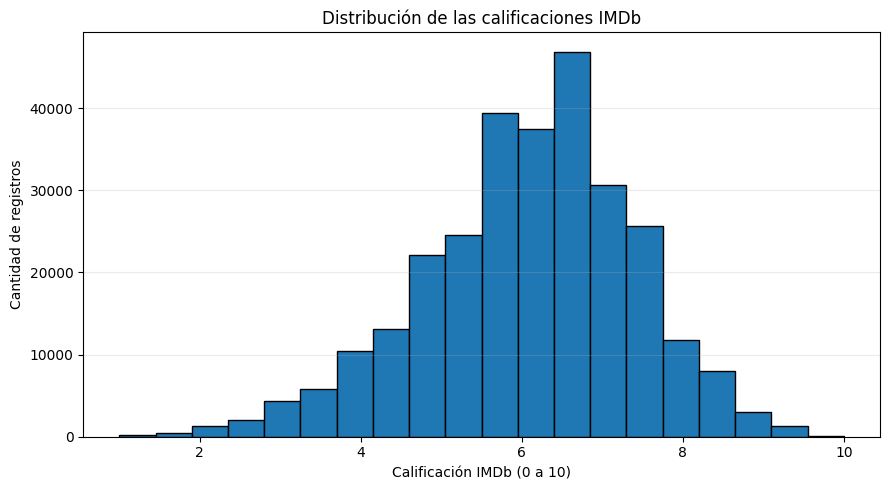

In [32]:
# ============================================================
# 30.3.1 HISTOGRAMA: DISTRIBUCIÓN DE CALIFICACIONES IMDb
# ============================================================

calificaciones = pd.to_numeric(df_eda["averageRating"], errors="coerce").dropna()
if calificaciones.empty:
    print("No hay calificaciones IMDb válidas para graficar.")
else:
    plt.figure(figsize=(9, 5))
    plt.hist(calificaciones, bins=20, edgecolor="black")
    plt.title("Distribución de las calificaciones IMDb")
    plt.xlabel("Calificación IMDb (0 a 10)")
    plt.ylabel("Cantidad de registros")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()
    plt.close()

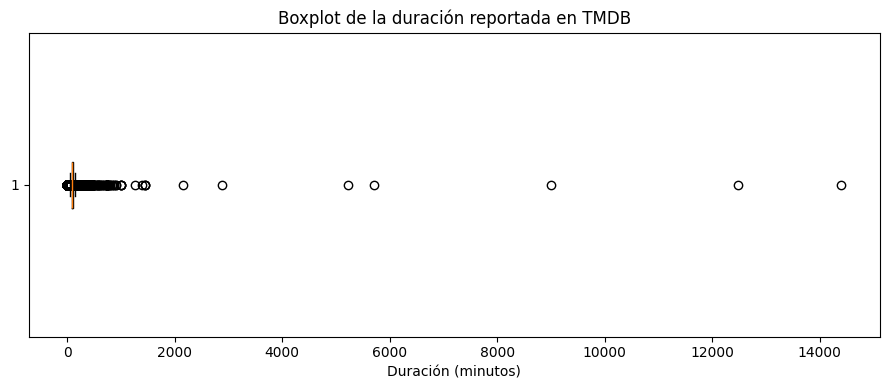

DIAGNÓSTICO DE POSIBLES OUTLIERS EN DURACIÓN
Q1: 81.00 minutos
Q3: 104.00 minutos
IQR: 23.00 minutos
Límite inferior (Q1 - 1.5×IQR): 46.50 minutos
Límite superior (Q3 + 1.5×IQR): 138.50 minutos
Valores fuera de los límites: 13,821
Valores por encima del límite superior: 11,722
Decisión: se conservan en esta etapa y se reportan para revisión; un valor extremo no demuestra por sí solo que sea erróneo.


In [33]:
# ============================================================
# 30.3.2 BOXPLOT: DISPERSIÓN Y POSIBLES VALORES EXTREMOS DE DURACIÓN
# ============================================================

duraciones = pd.to_numeric(df_eda["runtime"], errors="coerce").dropna().astype(float)
if duraciones.empty:
    print("No hay duraciones válidas para graficar.")
else:
    plt.figure(figsize=(9, 4))
    plt.boxplot(duraciones, vert=False, showfliers=True)
    plt.title("Boxplot de la duración reportada en TMDB")
    plt.xlabel("Duración (minutos)")
    plt.tight_layout()
    plt.show()
    plt.close()

    # Regla de 1.5 × IQR para señalar posibles valores extremos, sin eliminarlos.
    q1_runtime = float(duraciones.quantile(0.25))
    q3_runtime = float(duraciones.quantile(0.75))
    iqr_runtime = q3_runtime - q1_runtime
    limite_inferior_runtime = q1_runtime - 1.5 * iqr_runtime
    limite_superior_runtime = q3_runtime + 1.5 * iqr_runtime
    outliers_runtime = duraciones[
        (duraciones < limite_inferior_runtime)
        | (duraciones > limite_superior_runtime)
    ]
    outliers_superiores_runtime = duraciones[
        duraciones > limite_superior_runtime
    ]

    print("DIAGNÓSTICO DE POSIBLES OUTLIERS EN DURACIÓN")
    print("============================================")
    print(f"Q1: {q1_runtime:.2f} minutos")
    print(f"Q3: {q3_runtime:.2f} minutos")
    print(f"IQR: {iqr_runtime:.2f} minutos")
    print(f"Límite inferior (Q1 - 1.5×IQR): {limite_inferior_runtime:.2f} minutos")
    print(f"Límite superior (Q3 + 1.5×IQR): {limite_superior_runtime:.2f} minutos")
    print(f"Valores fuera de los límites: {len(outliers_runtime):,}")
    print(f"Valores por encima del límite superior: {len(outliers_superiores_runtime):,}")
    print("Decisión: se conservan en esta etapa y se reportan para revisión; un valor extremo no demuestra por sí solo que sea erróneo.")

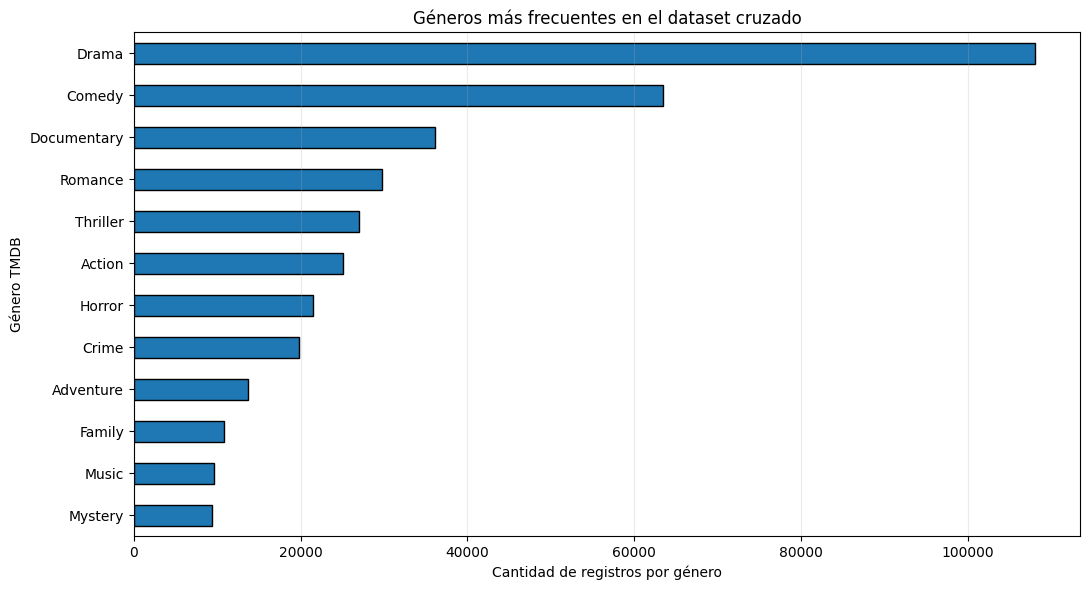

Nota: una misma película puede pertenecer a más de un género; las frecuencias por género no tienen que sumar el total de películas.


In [34]:
# ============================================================
# 30.3.3 GRÁFICO DE BARRAS: GÉNEROS MÁS FRECUENTES
# ============================================================

if frecuencia_generos.empty:
    print("No hay géneros TMDB disponibles para graficar.")
else:
    top_generos = frecuencia_generos.head(12).set_index("género")["cantidad de registros"]
    plt.figure(figsize=(11, 6))
    top_generos.sort_values().plot(kind="barh", edgecolor="black")
    plt.title("Géneros más frecuentes en el dataset cruzado")
    plt.xlabel("Cantidad de registros por género")
    plt.ylabel("Género TMDB")
    plt.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()
    plt.close()

print("Nota: una misma película puede pertenecer a más de un género; las frecuencias por género no tienen que sumar el total de películas.")

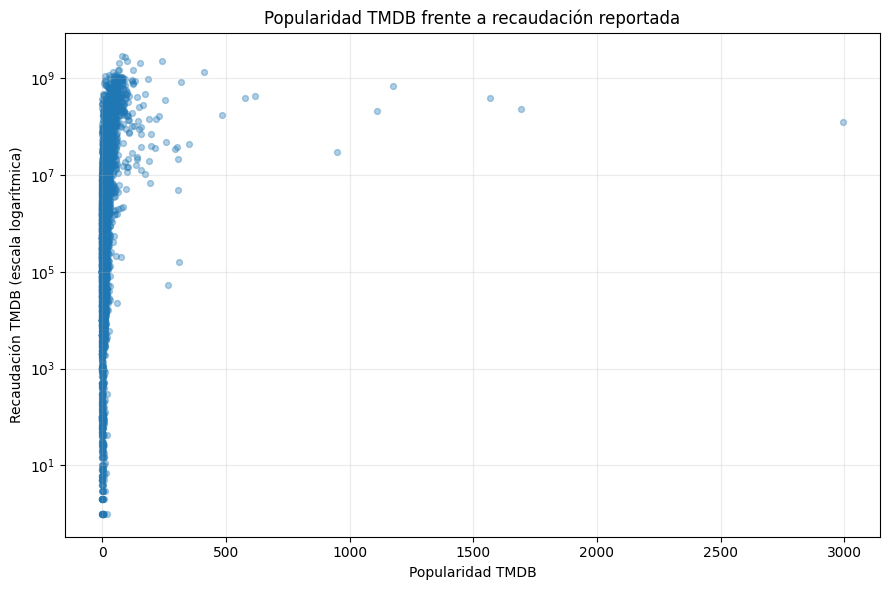

Puntos graficados: 8,000 de 15,855 registros válidos.


In [35]:
# ============================================================
# 30.3.4 SCATTER PLOT: POPULARIDAD VS. RECAUDACIÓN
# ============================================================

columnas_scatter = ["popularity", "revenue"]
df_scatter = df_eda.loc[
    df_eda["revenue"].notna() & df_eda["revenue"].gt(0),
    columnas_scatter
].copy()
df_scatter = df_scatter.dropna()
df_scatter = df_scatter[df_scatter["revenue"] > 0]

if df_scatter.empty:
    print("No hay registros completos con popularidad y recaudación positiva para el scatter plot.")
else:
    # Se limita la cantidad dibujada si hay demasiados puntos; la muestra es reproducible.
    limite_puntos = 8000
    df_scatter_grafico = (
        df_scatter.sample(n=limite_puntos, random_state=42)
        if len(df_scatter) > limite_puntos
        else df_scatter
    )
    plt.figure(figsize=(9, 6))
    plt.scatter(
        df_scatter_grafico["popularity"],
        df_scatter_grafico["revenue"],
        alpha=0.35,
        s=18
    )
    plt.yscale("log")
    plt.title("Popularidad TMDB frente a recaudación reportada")
    plt.xlabel("Popularidad TMDB")
    plt.ylabel("Recaudación TMDB (escala logarítmica)")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
    plt.close()
    print(f"Puntos graficados: {len(df_scatter_grafico):,} de {len(df_scatter):,} registros válidos.")

## 30.4 Comparación de recaudación por género

La frecuencia de un género no significa necesariamente que sus películas tengan mayor éxito en taquilla. Para comparar los géneros se revisa la **mediana de recaudación positiva reportada**, además de la media y el número de registros disponibles. La mediana ayuda a reducir el efecto de unas pocas películas con recaudaciones extraordinariamente altas.

El gráfico presenta solo los géneros que tienen al menos 30 registros con recaudación positiva. Estos resultados son descriptivos y no demuestran que el género, por sí solo, cause una mayor recaudación.

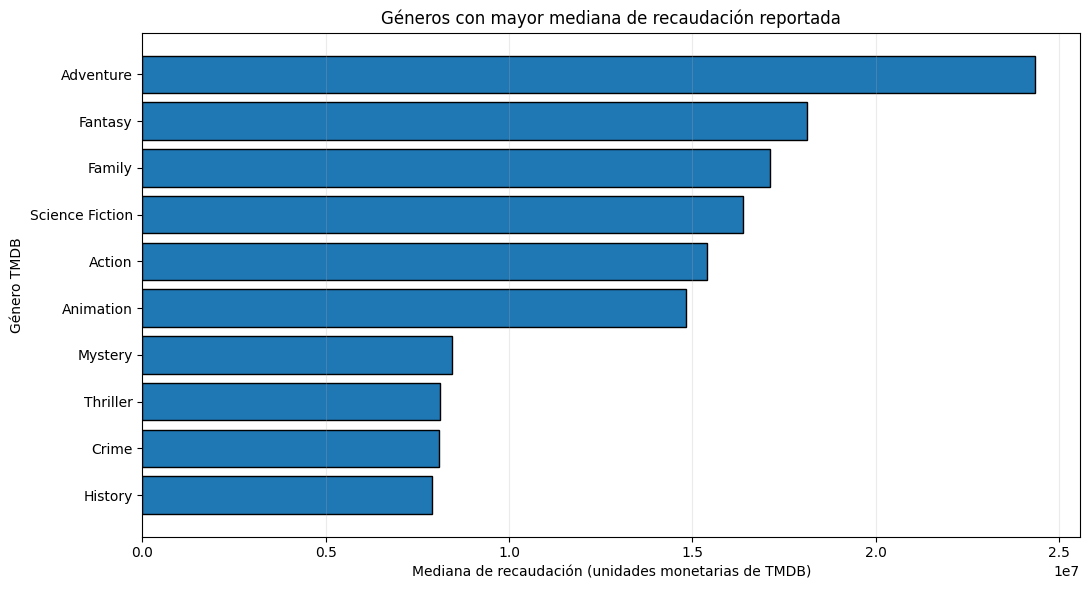

Tabla de referencia: cantidad de registros, media y mediana por género.


,peliculas_con_recaudacion,recaudacion_media,recaudacion_mediana
genero,,,
Adventure,2146,1.351740e+08,24358726.5
Fantasy,1287,1.120632e+08,18129854.0
Family,1449,9.358457e+07,17130489.0
Science Fiction,1265,1.133800e+08,16393000.0
Action,3227,9.151884e+07,15391979.0
Animation,919,1.037656e+08,14817006.0
Mystery,1144,4.150926e+07,8446945.0
Thriller,3297,4.758832e+07,8124257.0
Crime,2059,4.026103e+07,8094616.0


In [36]:
# ============================================================
# 30.4 GRÁFICO COMPLEMENTARIO: MEDIANA DE RECAUDACIÓN POR GÉNERO
# ============================================================

if resumen_recaudacion_genero.empty:
    print("No hay suficientes datos de taquilla por género para construir esta comparación.")
else:
    top_recaudacion_genero = resumen_recaudacion_genero.head(10).sort_values(
        "recaudacion_mediana", ascending=True
    )
    plt.figure(figsize=(11, 6))
    plt.barh(
        top_recaudacion_genero.index.astype(str),
        top_recaudacion_genero["recaudacion_mediana"],
        edgecolor="black"
    )
    plt.title("Géneros con mayor mediana de recaudación reportada")
    plt.xlabel("Mediana de recaudación (unidades monetarias de TMDB)")
    plt.ylabel("Género TMDB")
    plt.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()
    plt.close()

    print("Tabla de referencia: cantidad de registros, media y mediana por género.")
    display(resumen_recaudacion_genero.head(10).round(2))

## 30.5 Historia de hallazgos

La guía solicita entre 4 y 5 hallazgos que conecten una cifra concreta con la pregunta de negocio. Para no inventar resultados ni fijar cifras que puedan cambiar si se actualizan las fuentes, la siguiente celda redacta **cinco hallazgos a partir de las estadísticas calculadas en este mismo notebook**. La celda genera texto con formato Markdown para que se lea como una historia de resultados.

In [37]:
# ============================================================
# 30.5 HISTORIA DE HALLAZGOS BASADA EN LOS RESULTADOS REALES
# ============================================================

hallazgos_eda = []

# Hallazgo 1: cobertura de la recaudación.
porcentaje_sin_recaudacion = 100 - porcentaje_recaudacion
hallazgos_eda.append(
    f"**1. Cobertura de los datos de taquilla.** La base contiene **{filas_eda:,} registros**, "
    f"pero solo **{filas_con_recaudacion:,} ({porcentaje_recaudacion:.2f}%)** tienen una recaudación "
    f"positiva reportada; el **{porcentaje_sin_recaudacion:.2f}%** restante no tiene una recaudación "
    "positiva disponible para esta comparación. Por eso, los resultados de taquilla deben interpretarse "
    "con cautela: las películas con ingresos reportados podrían no representar a todo el catálogo."
)

# Hallazgo 2: media frente a mediana de calificación IMDb.
if "averageRating" in matriz_numerica.columns:
    ratings_eda = matriz_numerica["averageRating"].dropna()
else:
    ratings_eda = pd.Series(dtype=float)
if not ratings_eda.empty:
    media_rating_eda = float(ratings_eda.mean())
    mediana_rating_eda = float(ratings_eda.median())
    diferencia_rating_eda = abs(media_rating_eda - mediana_rating_eda)
    if diferencia_rating_eda <= 0.3:
        lectura_rating = "la media y la mediana son cercanas, lo que indica que el centro de la distribución no cambia mucho al usar una u otra medida"
    elif media_rating_eda > mediana_rating_eda:
        lectura_rating = "la media queda por encima de la mediana, por lo que valores altos elevan el promedio"
    else:
        lectura_rating = "la media queda por debajo de la mediana, por lo que valores bajos reducen el promedio"
    hallazgos_eda.append(
        f"**2. Calificación de las películas.** La media de IMDb es **{media_rating_eda:.2f}/10** y la mediana "
        f"es **{mediana_rating_eda:.2f}/10** (diferencia de **{diferencia_rating_eda:.2f}** puntos): {lectura_rating}. "
        "La calificación puede ayudar a describir la recepción de una película, pero debe contrastarse con la taquilla "
        "antes de usarla para decidir qué programar."
    )
else:
    hallazgos_eda.append(
        "**2. Calificación de las películas.** No hay suficientes calificaciones IMDb válidas para comparar la media y la mediana; se debe revisar la cobertura de este campo antes de interpretar su relación con la taquilla."
    )

# Hallazgo 3: género más frecuente.
if not frecuencia_generos.empty:
    genero_mas_frecuente = str(frecuencia_generos.iloc[0]["género"])
    cantidad_genero_frecuente = int(frecuencia_generos.iloc[0]["cantidad de registros"])
    porcentaje_genero_frecuente = 100 * cantidad_genero_frecuente / len(df_generos) if len(df_generos) else 0
    hallazgos_eda.append(
        f"**3. Género más representado.** El género más frecuente es **{genero_mas_frecuente}**, con **{cantidad_genero_frecuente:,}** "
        f"asignaciones de género ({porcentaje_genero_frecuente:.2f}% de las asignaciones registradas). Esto muestra qué tipo de película "
        "tiene mayor presencia en la base, pero no significa automáticamente que sea el género más taquillero; para eso se necesita la comparación de recaudación."
    )
else:
    hallazgos_eda.append(
        "**3. Género más representado.** No se encontraron géneros TMDB válidos para calcular frecuencias; sin esta información no se puede comparar la presencia de géneros en el catálogo."
    )

# Hallazgo 4: género con mayor mediana de recaudación, con una base mínima.
if not resumen_recaudacion_genero.empty:
    fila_top_genero = resumen_recaudacion_genero.iloc[0]
    nombre_top_genero = str(resumen_recaudacion_genero.index[0])
    mediana_top_genero = float(fila_top_genero["recaudacion_mediana"])
    cantidad_top_genero = int(fila_top_genero["peliculas_con_recaudacion"])
    hallazgos_eda.append(
        f"**4. Recaudación por género.** Entre los géneros con al menos 30 películas con recaudación positiva reportada, **{nombre_top_genero}** "
        f"presenta la mayor mediana de recaudación (**{mediana_top_genero:,.0f}**, con **{cantidad_top_genero:,}** registros). Es un candidato para estudiar con más detalle, "
        "pero la conclusión solo es válida para las películas con taquilla reportada y no prueba que el género cause ese resultado."
    )
else:
    hallazgos_eda.append(
        "**4. Recaudación por género.** Ningún género reunió al menos 30 registros con recaudación positiva reportada; la información disponible no permite comparar géneros de forma suficientemente estable con ese umbral."
    )

# Hallazgo 5: asociación entre popularidad/calificación y recaudación.
if (
    not df_correlacion.empty
    and "revenue" in df_correlacion.columns
    and ("popularity" in df_correlacion.columns or "averageRating" in df_correlacion.columns)
):
    correlaciones_hallazgo = df_correlacion.corr(method="spearman")
    partes_correlacion = []
    for variable, etiqueta in [
        ("popularity", "popularidad"),
        ("averageRating", "calificación IMDb")
    ]:
        if variable in correlaciones_hallazgo.columns:
            valor_corr = correlaciones_hallazgo.loc[variable, "revenue"]
            if pd.isna(valor_corr):
                partes_correlacion.append(f"no se pudo calcular la asociación con {etiqueta}")
            else:
                magnitud = abs(float(valor_corr))
                if magnitud < 0.20:
                    fuerza = "débil"
                elif magnitud < 0.40:
                    fuerza = "moderada"
                elif magnitud < 0.60:
                    fuerza = "marcada"
                else:
                    fuerza = "fuerte"
                direccion = "positiva" if valor_corr > 0 else "negativa" if valor_corr < 0 else "nula"
                partes_correlacion.append(
                    f"la asociación entre {etiqueta} y recaudación es {direccion} y {fuerza} (Spearman = {float(valor_corr):.3f})"
                )
    resumen_corr = "; mientras que ".join(partes_correlacion) if partes_correlacion else "no se pudieron calcular asociaciones con las variables disponibles"
    hallazgos_eda.append(
        f"**5. Popularidad y calificación frente a taquilla.** En las películas con recaudación positiva reportada, {resumen_corr}. "
        "Estas asociaciones sirven para orientar el análisis, pero no demuestran causalidad ni garantizan la demanda futura en un cine específico."
    )
else:
    hallazgos_eda.append(
        "**5. Popularidad y calificación frente a taquilla.** No hay suficientes registros completos para calcular las correlaciones de Spearman; primero debe mejorarse la cobertura de recaudación o de las variables comparadas."
    )

# Mostrar exactamente cinco hallazgos redactados en lenguaje natural.
texto_hallazgos = "## Hallazgos del análisis exploratorio\n\n" + "\n\n".join(
    f"{i}. {hallazgo.split('. ', 1)[1] if '. ' in hallazgo else hallazgo}"
    for i, hallazgo in enumerate(hallazgos_eda, start=1)
)
# Mantener los encabezados en negrita y la numeración con formato Markdown.
texto_hallazgos = "## Hallazgos del análisis exploratorio\n\n" + "\n\n".join(
    f"{hallazgo}" for hallazgo in hallazgos_eda
)
display(Markdown(texto_hallazgos))

## Hallazgos del análisis exploratorio

**1. Cobertura de los datos de taquilla.** La base contiene **288,306 registros**, pero solo **15,855 (5.50%)** tienen una recaudación positiva reportada; el **94.50%** restante no tiene una recaudación positiva disponible para esta comparación. Por eso, los resultados de taquilla deben interpretarse con cautela: las películas con ingresos reportados podrían no representar a todo el catálogo.

**2. Calificación de las películas.** La media de IMDb es **6.06/10** y la mediana es **6.20/10** (diferencia de **0.14** puntos): la media y la mediana son cercanas, lo que indica que el centro de la distribución no cambia mucho al usar una u otra medida. La calificación puede ayudar a describir la recepción de una película, pero debe contrastarse con la taquilla antes de usarla para decidir qué programar.

**3. Género más representado.** El género más frecuente es **Drama**, con **108,067** asignaciones de género (25.99% de las asignaciones registradas). Esto muestra qué tipo de película tiene mayor presencia en la base, pero no significa automáticamente que sea el género más taquillero; para eso se necesita la comparación de recaudación.

**4. Recaudación por género.** Entre los géneros con al menos 30 películas con recaudación positiva reportada, **Adventure** presenta la mayor mediana de recaudación (**24,358,726**, con **2,146** registros). Es un candidato para estudiar con más detalle, pero la conclusión solo es válida para las películas con taquilla reportada y no prueba que el género cause ese resultado.

**5. Popularidad y calificación frente a taquilla.** En las películas con recaudación positiva reportada, la asociación entre popularidad y recaudación es positiva y fuerte (Spearman = 0.707); mientras que la asociación entre calificación IMDb y recaudación es positiva y débil (Spearman = 0.181). Estas asociaciones sirven para orientar el análisis, pero no demuestran causalidad ni garantizan la demanda futura en un cine específico.

# 31. Ingeniería de características y pipeline

En esta etapa se preparan variables que aportan información útil para estudiar las características asociadas al éxito de las películas. Se trabaja sobre `peliculas_cruzadas_calidad`, que es el dataset resultante de la etapa de calidad de datos.

**Importante:** se crea una copia llamada `peliculas_caracteristicas`; por tanto, las tablas y los resultados de adquisición, calidad de datos y análisis exploratorio de las secciones anteriores no se modifican.

El proceso incluye cuatro partes: creación de variables derivadas, codificación de variables categóricas, escalado de variables numéricas y construcción de un pipeline reproducible.

## 31.1 Ingeniería de características: creación de variables derivadas

Se crean cinco variables derivadas con una utilidad concreta para el proyecto:

1. **`decada_lanzamiento`:** agrupa las películas por década. Se toma primero el año de `release_date` de TMDB y, cuando no está disponible, se utiliza `startYear` de IMDb.
2. **`cantidad_generos`:** cuenta los géneros distintos asociados a cada película.
3. **`genero_principal`:** toma el primer género disponible de TMDB; si no existe, utiliza el primer género de IMDb. Es una categoría operativa para el análisis, no una afirmación de que ese género sea necesariamente el dominante.
4. **`categoria_duracion`:** clasifica las películas en cortas (menos de 90 minutos), medias (90 a 150 minutos) y largas (más de 150 minutos). Son rangos de trabajo definidos para comparar grupos.
5. **`votos_log`:** aplica `log(1 + numVotes)` para reducir la asimetría que suele presentar la cantidad de votos.

Estas variables se generan desde las columnas originales y se vuelven a calcular desde cero cada vez que se ejecuta la celda, evitando duplicaciones al correr el notebook más de una vez.

In [38]:
# ============================================================
# 31.1 CREACIÓN DE VARIABLES DERIVADAS
# ============================================================

if "peliculas_cruzadas_calidad" not in globals():
    raise NameError(
        "No se encontró 'peliculas_cruzadas_calidad'. "
        "Ejecuta primero las secciones de adquisición y calidad de datos."
    )

# Se parte siempre de la tabla limpia y se trabaja sobre una copia.
peliculas_caracteristicas = peliculas_cruzadas_calidad.copy()

columnas_base_requeridas = ["release_date", "startYear", "runtime", "numVotes"]
columnas_base_faltantes = [
    columna for columna in columnas_base_requeridas
    if columna not in peliculas_caracteristicas.columns
]
if columnas_base_faltantes:
    raise KeyError(
        "Faltan columnas necesarias para crear las características: "
        + ", ".join(columnas_base_faltantes)
    )

# ------------------------------------------------------------
# 1) Década de lanzamiento
# ------------------------------------------------------------
# Se utiliza primero la fecha TMDB y se completa con el año IMDb.
fecha_tmdb_caract = pd.to_datetime(
    peliculas_caracteristicas["release_date"],
    errors="coerce"
)
anio_tmdb_caract = fecha_tmdb_caract.dt.year
anio_imdb_caract = pd.to_numeric(
    peliculas_caracteristicas["startYear"],
    errors="coerce"
)
anio_lanzamiento_caract = anio_tmdb_caract.fillna(anio_imdb_caract)
decada_caract = (anio_lanzamiento_caract // 10) * 10

peliculas_caracteristicas["decada_lanzamiento"] = pd.Series(
    [f"{int(valor)}s" if pd.notna(valor) else pd.NA for valor in decada_caract],
    index=peliculas_caracteristicas.index,
    dtype="string"
)

# ------------------------------------------------------------
# 2) Cantidad de géneros y género principal
# ------------------------------------------------------------
def separar_generos_caracteristica(valor):
    """Convierte una cadena de géneros separados por comas en una lista limpia."""
    if pd.isna(valor):
        return []

    texto = str(valor).strip()
    if texto.lower() in {"", r"\n", "nan", "none", "<na>"}:
        return []

    return [
        genero.strip()
        for genero in texto.split(",")
        if genero.strip() and genero.strip().lower() not in {r"\n", "nan", "none"}
    ]

if "genres_tmdb" in peliculas_caracteristicas.columns:
    generos_tmdb_caract = peliculas_caracteristicas["genres_tmdb"].apply(
        separar_generos_caracteristica
    )
else:
    generos_tmdb_caract = pd.Series(
        [[] for _ in range(len(peliculas_caracteristicas))],
        index=peliculas_caracteristicas.index
    )

if "genres_imdb" in peliculas_caracteristicas.columns:
    generos_imdb_caract = peliculas_caracteristicas["genres_imdb"].apply(
        separar_generos_caracteristica
    )
else:
    generos_imdb_caract = pd.Series(
        [[] for _ in range(len(peliculas_caracteristicas))],
        index=peliculas_caracteristicas.index
    )

# TMDB tiene prioridad por consistencia con el EDA. IMDb funciona como respaldo.
generos_por_pelicula = [
    lista_tmdb if lista_tmdb else lista_imdb
    for lista_tmdb, lista_imdb in zip(generos_tmdb_caract, generos_imdb_caract)
]

# Se eliminan repeticiones conservando el orden de aparición.
generos_por_pelicula = [
    list(dict.fromkeys(lista)) for lista in generos_por_pelicula
]

peliculas_caracteristicas["cantidad_generos"] = pd.Series(
    [len(lista) for lista in generos_por_pelicula],
    index=peliculas_caracteristicas.index,
    dtype="Int64"
)
peliculas_caracteristicas["genero_principal"] = pd.Series(
    [lista[0] if lista else pd.NA for lista in generos_por_pelicula],
    index=peliculas_caracteristicas.index,
    dtype="string"
)

# ------------------------------------------------------------
# 3) Categoría de duración
# ------------------------------------------------------------
duracion_caract = pd.to_numeric(
    peliculas_caracteristicas["runtime"],
    errors="coerce"
)
categoria_duracion_caract = pd.Series(
    "Sin información",
    index=peliculas_caracteristicas.index,
    dtype="object"
)
categoria_duracion_caract.loc[
    duracion_caract.notna() & duracion_caract.gt(0) & duracion_caract.lt(90)
] = "Corta (<90 min)"
categoria_duracion_caract.loc[
    duracion_caract.between(90, 150, inclusive="both")
] = "Media (90-150 min)"
categoria_duracion_caract.loc[duracion_caract.gt(150)] = "Larga (>150 min)"

peliculas_caracteristicas["categoria_duracion"] = categoria_duracion_caract

# ------------------------------------------------------------
# 4) Transformación logarítmica de los votos IMDb
# ------------------------------------------------------------
votos_caract = pd.to_numeric(
    peliculas_caracteristicas["numVotes"],
    errors="coerce"
)
# Los conteos negativos no son válidos; se marcan como faltantes.
votos_caract = votos_caract.where(votos_caract.ge(0))
peliculas_caracteristicas["votos_log"] = np.log1p(
    votos_caract.astype("float64")
)

# Resumen de las variables creadas.
columnas_derivadas = [
    "decada_lanzamiento",
    "cantidad_generos",
    "genero_principal",
    "categoria_duracion",
    "votos_log"
]

print("VARIABLES DERIVADAS CREADAS")
print("===========================")
print("Filas conservadas:", f"{len(peliculas_caracteristicas):,}")
print("Nuevas variables:", len(columnas_derivadas))
display(peliculas_caracteristicas[columnas_derivadas].head())

# Diccionario breve que documenta el sentido de cada característica.
diccionario_caracteristicas = pd.DataFrame([
    {
        "variable_derivada": "decada_lanzamiento",
        "regla_de_creacion": "Año de release_date; si falta, startYear; luego se agrupa por década.",
        "utilidad_para_el_proyecto": "Comparar características y resultados entre épocas de estreno."
    },
    {
        "variable_derivada": "cantidad_generos",
        "regla_de_creacion": "Cantidad de géneros distintos encontrados en TMDB o, como respaldo, IMDb.",
        "utilidad_para_el_proyecto": "Analizar si la diversidad de géneros se relaciona con el desempeño."
    },
    {
        "variable_derivada": "genero_principal",
        "regla_de_creacion": "Primer género informado por TMDB; si no existe, primer género de IMDb.",
        "utilidad_para_el_proyecto": "Codificar una categoría de género por película para comparaciones."
    },
    {
        "variable_derivada": "categoria_duracion",
        "regla_de_creacion": "Corta: menos de 90 min; media: 90-150 min; larga: más de 150 min.",
        "utilidad_para_el_proyecto": "Comparar películas por rangos de duración."
    },
    {
        "variable_derivada": "votos_log",
        "regla_de_creacion": "Logaritmo natural de 1 + numVotes, para votos no negativos.",
        "utilidad_para_el_proyecto": "Representar la cantidad de votos con menor asimetría."
    }
])

display(diccionario_caracteristicas)

VARIABLES DERIVADAS CREADAS
Filas conservadas: 288,306
Nuevas variables: 5


,decada_lanzamiento,cantidad_generos,genero_principal,categoria_duracion,votos_log
0,1890s,1,Romance,Corta (<90 min),5.488938
1,1890s,1,Documentary,Corta (<90 min),6.428105
2,1900s,4,Crime,Corta (<90 min),7.009409
3,1900s,1,Drama,Media (90-150 min),3.784190
4,1900s,1,Drama,Corta (<90 min),3.663562


,variable_derivada,regla_de_creacion,utilidad_para_el_proyecto
0,decada_lanzamiento,"Año de release_date; si falta, startYear; lueg...",Comparar características y resultados entre ép...
1,cantidad_generos,Cantidad de géneros distintos encontrados en T...,Analizar si la diversidad de géneros se relaci...
2,genero_principal,Primer género informado por TMDB; si no existe...,Codificar una categoría de género por película...
3,categoria_duracion,Corta: menos de 90 min; media: 90-150 min; lar...,Comparar películas por rangos de duración.
4,votos_log,"Logaritmo natural de 1 + numVotes, para votos ...",Representar la cantidad de votos con menor asi...


## 31.2 Codificación de variables categóricas

Los algoritmos de aprendizaje automático necesitan trabajar con valores numéricos. Por eso, las categorías `genero_principal`, `decada_lanzamiento` y `categoria_duracion` se transforman mediante **One-Hot Encoding**.

Cada categoría se convierte en una columna indicadora. Se configura `handle_unknown="ignore"` para que el pipeline pueda transformar películas con una categoría que no haya aparecido durante el ajuste, sin detener la ejecución.

Antes de codificar, los valores categóricos faltantes se completan con la etiqueta **“Sin información”**. La codificación se ajustará posteriormente solo con los datos de entrenamiento, no con los datos de prueba.

In [39]:
# ============================================================
# 31.2 PREPARACIÓN Y CODIFICACIÓN DE VARIABLES CATEGÓRICAS
# ============================================================

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

columnas_categoricas_pipeline = [
    "genero_principal",
    "decada_lanzamiento",
    "categoria_duracion"
]

columnas_numericas_pipeline = [
    "averageRating",
    "popularity",
    "runtime",
    "cantidad_generos",
    "votos_log"
]

columnas_entrada_pipeline = (
    columnas_numericas_pipeline + columnas_categoricas_pipeline
)

columnas_faltantes_pipeline = [
    columna for columna in columnas_entrada_pipeline
    if columna not in peliculas_caracteristicas.columns
]
if columnas_faltantes_pipeline:
    raise KeyError(
        "No se encontraron todas las variables requeridas para el pipeline: "
        + ", ".join(columnas_faltantes_pipeline)
    )

# Matriz de entrada: contiene solo características, nunca la recaudación.
X_caracteristicas = peliculas_caracteristicas[columnas_entrada_pipeline].copy()

# Asegurar datos numéricos compatibles con Scikit-learn.
for columna in columnas_numericas_pipeline:
    X_caracteristicas[columna] = pd.to_numeric(
        X_caracteristicas[columna],
        errors="coerce"
    ).astype("float64")

# Asegurar que los faltantes categóricos se representen como np.nan.
for columna in columnas_categoricas_pipeline:
    X_caracteristicas[columna] = X_caracteristicas[columna].astype("object")
    X_caracteristicas[columna] = X_caracteristicas[columna].where(
        pd.notna(X_caracteristicas[columna]),
        np.nan
    )

# Verificación explícita para evitar que la variable objetivo se filtre
# dentro de las variables predictoras.
if "revenue" in X_caracteristicas.columns:
    raise AssertionError(
        "La variable revenue no debe estar dentro de X_caracteristicas."
    )

# Compatibilidad con distintas versiones de Scikit-learn:
# sparse_output se utiliza en versiones recientes y sparse en versiones anteriores.
def crear_codificador_one_hot():
    try:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        )
    except TypeError:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse=True
        )


def crear_pipeline_categorico():
    """Imputa categorías faltantes y aplica One-Hot Encoding."""
    return Pipeline(steps=[
        (
            "imputador",
            SimpleImputer(
                strategy="constant",
                fill_value="Sin información"
            )
        ),
        ("codificador_one_hot", crear_codificador_one_hot())
    ])

# Se crea el transformador categórico que luego se integrará al pipeline general.
pipeline_categorico = crear_pipeline_categorico()

print("VARIABLES QUE SE CODIFICARÁN")
print("============================")
for columna in columnas_categoricas_pipeline:
    print(f"- {columna}: {X_caracteristicas[columna].nunique(dropna=True):,} categorías observadas")

print("\nCodificador configurado: OneHotEncoder(handle_unknown='ignore').")
print("Los faltantes se completarán con la categoría 'Sin información'.")

VARIABLES QUE SE CODIFICARÁN
- genero_principal: 26 categorías observadas
- decada_lanzamiento: 15 categorías observadas
- categoria_duracion: 4 categorías observadas

Codificador configurado: OneHotEncoder(handle_unknown='ignore').
Los faltantes se completarán con la categoría 'Sin información'.


## 31.3 Escalado de variables numéricas

Las variables numéricas seleccionadas son `averageRating`, `popularity`, `runtime`, `cantidad_generos` y `votos_log`. Se utiliza **RobustScaler**, que centra cada variable usando la mediana y la escala mediante el rango intercuartílico.

Se elige este escalador porque en el análisis exploratorio se observaron distribuciones dispersas y posibles valores extremos, especialmente en popularidad, duración y cantidad de votos. La imputación de valores faltantes se realiza con la mediana calculada exclusivamente sobre el conjunto de entrenamiento.

La variable `popularity` es especialmente relevante para la pregunta de negocio, pero se escalan también las demás variables numéricas para que queden en magnitudes comparables.

In [40]:
# ============================================================
# 31.3 ESCALADO DE VARIABLES NUMÉRICAS
# ============================================================

from sklearn.preprocessing import RobustScaler


def crear_pipeline_numerico():
    """Imputa valores faltantes y escala las variables numéricas."""
    return Pipeline(steps=[
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", RobustScaler())
    ])


# Transformador numérico que se integrará con la codificación categórica.
pipeline_numerico = crear_pipeline_numerico()

print("VARIABLES NUMÉRICAS QUE SE ESCALARÁN")
print("====================================")
for columna in columnas_numericas_pipeline:
    faltantes = int(X_caracteristicas[columna].isna().sum())
    print(
        f"- {columna}: {faltantes:,} valores faltantes "
        f"({X_caracteristicas[columna].isna().mean() * 100:.2f}%)"
    )

print("\nEscalador configurado: RobustScaler.")
print("Los parámetros de escala se aprenderán solamente con el conjunto de entrenamiento.")

VARIABLES NUMÉRICAS QUE SE ESCALARÁN
- averageRating: 0 valores faltantes (0.00%)
- popularity: 0 valores faltantes (0.00%)
- runtime: 44,925 valores faltantes (15.58%)
- cantidad_generos: 0 valores faltantes (0.00%)
- votos_log: 0 valores faltantes (0.00%)

Escalador configurado: RobustScaler.
Los parámetros de escala se aprenderán solamente con el conjunto de entrenamiento.


## 31.4 Pipeline reproducible

Se integran los dos procesos anteriores mediante `ColumnTransformer` y `Pipeline` de Scikit-learn. La función `ejecutar_pipeline_caracteristicas()` realiza de forma ordenada la separación de entrenamiento y prueba, el ajuste de los imputadores, la codificación de las categorías y el escalado numérico.

Se utiliza `random_state=42` para que la división de los registros sea reproducible. El pipeline se ajusta únicamente con entrenamiento y luego transforma prueba; así se evita utilizar información del conjunto de prueba para calcular medianas, escalas o categorías.

**Criterios de selección:**
- `revenue` se conserva fuera de la matriz de entrada porque es la variable de resultado que el proyecto busca estudiar; incluirla como predictor produciría filtración de información.
- `budget` no se incluye en esta primera matriz porque en la etapa de calidad se encontró que la mayoría de los registros no tenían presupuesto reportado. Se puede evaluar más adelante con una estrategia específica para su alta ausencia.
- Los identificadores y títulos se excluyen porque identifican películas, pero no son por sí mismos características numéricas o categóricas que deban aprenderse en esta transformación.

Al final se ejecuta dos veces el mismo procedimiento sobre una muestra fija y se comparan las matrices obtenidas para comprobar que produce la misma salida.

In [41]:
# ============================================================
# 31.4 PIPELINE REPRODUCIBLE DE CARACTERÍSTICAS
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from scipy import sparse


def crear_pipeline_caracteristicas():
    """Construye desde cero el pipeline de imputación, codificación y escalado."""
    preprocesador = ColumnTransformer(
        transformers=[
            (
                "numericas",
                crear_pipeline_numerico(),
                columnas_numericas_pipeline
            ),
            (
                "categoricas",
                crear_pipeline_categorico(),
                columnas_categoricas_pipeline
            )
        ],
        remainder="drop",
        sparse_threshold=0.3
    )

    return Pipeline(steps=[
        ("preprocesador", preprocesador)
    ])


def ejecutar_pipeline_caracteristicas(
    X,
    test_size=0.20,
    random_state=42
):
    """Divide los datos, ajusta el pipeline con entrenamiento y transforma prueba."""
    if not isinstance(X, pd.DataFrame):
        raise TypeError("X debe ser un DataFrame de pandas.")
    if len(X) < 5:
        raise ValueError("Se necesitan al menos cinco registros para ejecutar el pipeline.")

    X_entrenamiento, X_prueba = train_test_split(
        X,
        test_size=test_size,
        random_state=random_state
    )

    pipeline = crear_pipeline_caracteristicas()
    X_entrenamiento_transformado = pipeline.fit_transform(X_entrenamiento)
    X_prueba_transformado = pipeline.transform(X_prueba)

    return {
        "pipeline": pipeline,
        "X_entrenamiento": X_entrenamiento,
        "X_prueba": X_prueba,
        "X_entrenamiento_transformado": X_entrenamiento_transformado,
        "X_prueba_transformado": X_prueba_transformado
    }


# Ejecutar el pipeline sobre todas las películas.
resultado_pipeline = ejecutar_pipeline_caracteristicas(
    X_caracteristicas,
    test_size=0.20,
    random_state=42
)

pipeline_caracteristicas = resultado_pipeline["pipeline"]
X_entrenamiento = resultado_pipeline["X_entrenamiento"]
X_prueba = resultado_pipeline["X_prueba"]
X_entrenamiento_transformado = resultado_pipeline["X_entrenamiento_transformado"]
X_prueba_transformado = resultado_pipeline["X_prueba_transformado"]

# Obtener los nombres generados después de codificar las categorías.
nombres_caracteristicas_transformadas = (
    pipeline_caracteristicas
    .named_steps["preprocesador"]
    .get_feature_names_out()
)

# ------------------------------------------------------------
# Comprobación de reproducibilidad
# ------------------------------------------------------------
def matrices_iguales(matriz_a, matriz_b):
    """Compara matrices densas o dispersas sin convertir matrices grandes a densas."""
    if sparse.issparse(matriz_a) and sparse.issparse(matriz_b):
        diferencia = (matriz_a - matriz_b).tocsr()
        diferencia.eliminate_zeros()
        return diferencia.nnz == 0

    if sparse.issparse(matriz_a):
        matriz_a = matriz_a.toarray()
    if sparse.issparse(matriz_b):
        matriz_b = matriz_b.toarray()

    return np.array_equal(matriz_a, matriz_b)


# Se fija una muestra para repetir la función sin volver a procesar
# toda la base dos veces. La semilla garantiza la misma partición.
muestra_reproducibilidad = X_caracteristicas.sample(
    n=min(1000, len(X_caracteristicas)),
    random_state=42
)

resultado_repeticion_1 = ejecutar_pipeline_caracteristicas(
    muestra_reproducibilidad,
    test_size=0.20,
    random_state=42
)
resultado_repeticion_2 = ejecutar_pipeline_caracteristicas(
    muestra_reproducibilidad,
    test_size=0.20,
    random_state=42
)

misma_particion = (
    resultado_repeticion_1["X_entrenamiento"].index.equals(
        resultado_repeticion_2["X_entrenamiento"].index
    )
    and resultado_repeticion_1["X_prueba"].index.equals(
        resultado_repeticion_2["X_prueba"].index
    )
)

misma_salida_entrenamiento = matrices_iguales(
    resultado_repeticion_1["X_entrenamiento_transformado"],
    resultado_repeticion_2["X_entrenamiento_transformado"]
)
misma_salida_prueba = matrices_iguales(
    resultado_repeticion_1["X_prueba_transformado"],
    resultado_repeticion_2["X_prueba_transformado"]
)

pipeline_reproducible = (
    misma_particion
    and misma_salida_entrenamiento
    and misma_salida_prueba
)

print("RESULTADO DEL PIPELINE")
print("======================")
print(f"Registros originales para características: {len(X_caracteristicas):,}")
print(f"Registros de entrenamiento: {len(X_entrenamiento):,}")
print(f"Registros de prueba: {len(X_prueba):,}")
print(f"Variables antes de transformar: {X_caracteristicas.shape[1]}")
print(f"Variables después de codificar y escalar: {len(nombres_caracteristicas_transformadas):,}")
print("Forma de la matriz de entrenamiento:", X_entrenamiento_transformado.shape)
print("Forma de la matriz de prueba:", X_prueba_transformado.shape)
print("Tipo de matriz resultante:", type(X_entrenamiento_transformado).__name__)
print("\n¿La misma entrada produce la misma salida al repetir el proceso?", pipeline_reproducible)

assert pipeline_reproducible, (
    "La comprobación de reproducibilidad no fue satisfactoria. "
    "Revisa la semilla y los pasos del pipeline."
)
print("✓ Pipeline reproducible: división, codificación y escalado generan el mismo resultado.")

# Mostrar los parámetros aprendidos por RobustScaler sobre entrenamiento.
preprocesador_ajustado = pipeline_caracteristicas.named_steps["preprocesador"]
pipeline_numerico_ajustado = preprocesador_ajustado.named_transformers_["numericas"]
escalador_ajustado = pipeline_numerico_ajustado.named_steps["escalador"]

resumen_escalado = pd.DataFrame({
    "variable_numerica": columnas_numericas_pipeline,
    "mediana_entrenamiento": escalador_ajustado.center_,
    "rango_intercuartil": escalador_ajustado.scale_
})
print("\nPARÁMETROS DEL ESCALADO (APRENDIDOS SOLO CON ENTRENAMIENTO)")
display(resumen_escalado.round(4))

# Vista pequeña de la matriz transformada, sin convertir toda la matriz dispersa.
filas_muestra = min(5, X_entrenamiento_transformado.shape[0])
columnas_muestra = min(12, len(nombres_caracteristicas_transformadas))
if sparse.issparse(X_entrenamiento_transformado):
    valores_muestra = X_entrenamiento_transformado[:filas_muestra, :columnas_muestra].toarray()
else:
    valores_muestra = X_entrenamiento_transformado[:filas_muestra, :columnas_muestra]

print("\nMUESTRA DE LAS CARACTERÍSTICAS TRANSFORMADAS")
display(pd.DataFrame(
    valores_muestra,
    columns=nombres_caracteristicas_transformadas[:columnas_muestra]
))

RESULTADO DEL PIPELINE
Registros originales para características: 288,306
Registros de entrenamiento: 230,644
Registros de prueba: 57,662
Variables antes de transformar: 8
Variables después de codificar y escalar: 52
Forma de la matriz de entrenamiento: (230644, 52)
Forma de la matriz de prueba: (57662, 52)
Tipo de matriz resultante: csr_matrix

¿La misma entrada produce la misma salida al repetir el proceso? True
✓ Pipeline reproducible: división, codificación y escalado generan el mismo resultado.

PARÁMETROS DEL ESCALADO (APRENDIDOS SOLO CON ENTRENAMIENTO)


,variable_numerica,mediana_entrenamiento,rango_intercuartil
0,averageRating,6.2000,1.7000
1,popularity,0.9860,1.3820
2,runtime,91.0000,16.0000
3,cantidad_generos,1.0000,1.0000
4,votos_log,4.5433,2.7486



MUESTRA DE LAS CARACTERÍSTICAS TRANSFORMADAS


,numericas__averageRating,numericas__popularity,numericas__runtime,numericas__cantidad_generos,numericas__votos_log,categoricas__genero_principal_Action,categoricas__genero_principal_Adult,categoricas__genero_principal_Adventure,categoricas__genero_principal_Animation,categoricas__genero_principal_Biography,categoricas__genero_principal_Comedy,categoricas__genero_principal_Crime
0,0.352941,0.299566,-0.3750,2.0,0.238377,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-1.058824,0.299566,0.0000,0.0,0.394502,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-1.117647,1.282923,0.9375,0.0,0.195776,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,-0.058824,-0.279305,0.0000,1.0,-0.748887,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.176471,-0.279305,0.0000,0.0,1.028043,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Conclusión de ingeniería de características y pipeline

Se generaron cinco características relacionadas con la época de estreno, los géneros, la duración y la participación de usuarios. Las categorías se preparan con One-Hot Encoding y las variables numéricas se imputan y escalan con RobustScaler.

El proceso quedó encapsulado en las funciones `crear_pipeline_caracteristicas()` y `ejecutar_pipeline_caracteristicas()`. La división fija con `random_state=42`, el ajuste de transformaciones solo sobre entrenamiento y la comprobación de dos ejecuciones permiten repetir el proceso con la misma entrada y obtener la misma salida.

La matriz resultante queda preparada para una etapa posterior de modelado. **Esta sección no entrena todavía un modelo ni afirma qué películas serán exitosas**; la definición de la variable objetivo y la evaluación predictiva deberán realizarse en la etapa correspondiente.

# 32. Técnica complementaria: detección de anomalías

En esta sección se aplica una técnica de minería de datos no supervisada para identificar películas que presentan combinaciones poco habituales de características. Se utiliza **Isolation Forest**, un algoritmo que detecta observaciones que pueden aislarse con mayor facilidad que la mayoría de los registros.

El objetivo es complementar el análisis exploratorio y la ingeniería de características, encontrando películas con perfiles atípicos de calificación, popularidad, duración, cantidad de géneros y participación de usuarios. Una anomalía no significa necesariamente que el registro esté equivocado ni que la película sea buena o mala; significa que su combinación de datos es poco común frente al conjunto analizado.

**Importante:** se trabaja sobre una selección de columnas de `peliculas_caracteristicas`. La tabla original, `peliculas_cruzadas_calidad` y las secciones anteriores no se modifican.

## 32.1 Diseño del experimento y variables seleccionadas

**Técnica:** Isolation Forest (detección no supervisada de anomalías).

**¿Por qué se selecciona?** El proyecto contiene variables numéricas de películas y no cuenta con una etiqueta que indique cuáles registros son anomalías. Isolation Forest permite buscar observaciones inusuales sin necesitar una clasificación previa.

**Variables de entrada:**

- `averageRating`: calificación promedio de IMDb.
- `vote_average`: calificación promedio de TMDB.
- `popularity`: popularidad de TMDB, transformada con `log1p` para reducir su asimetría.
- `runtime`: duración en minutos, ya tratada en la etapa de calidad.
- `cantidad_generos`: cantidad de géneros de la película, creada en la sección 31.
- `votos_log`: logaritmo de la cantidad de votos IMDb, creado en la sección 31.
- `votos_tmdb_log`: logaritmo de la cantidad de votos TMDB, calculado en esta sección.

No se utilizan `revenue` ni `budget`: tienen una alta proporción de información no reportada y son variables financieras que no se necesitan para detectar perfiles atípicos entre las características seleccionadas. Tampoco se utilizan títulos ni identificadores como variables del algoritmo; se conservan únicamente para interpretar los resultados.

Los valores faltantes de las variables numéricas se completan con la mediana. Para evitar que los registros con muy poca información sean clasificados principalmente por la imputación, se analizan únicamente las películas que tienen al menos la mitad de las variables seleccionadas disponibles (y como mínimo tres). Esta selección solo aplica al experimento; no elimina filas del dataset principal.

In [42]:
# ============================================================
# 32.2 PREPARACIÓN DE DATOS PARA DETECCIÓN DE ANOMALÍAS
# ============================================================

from sklearn.impute import SimpleImputer
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt

if "peliculas_caracteristicas" not in globals():
    raise NameError(
        "No se encontró 'peliculas_caracteristicas'. "
        "Ejecuta primero las secciones anteriores hasta la sección 31."
    )

columnas_necesarias_anomalias = [
    "averageRating",
    "vote_average",
    "popularity",
    "runtime",
    "cantidad_generos",
    "votos_log",
    "vote_count"
]

columnas_faltantes_anomalias = [
    columna for columna in columnas_necesarias_anomalias
    if columna not in peliculas_caracteristicas.columns
]
if columnas_faltantes_anomalias:
    raise KeyError(
        "Faltan columnas requeridas para el experimento: "
        + ", ".join(columnas_faltantes_anomalias)
    )

# Se crea una tabla de trabajo independiente con variables de contexto
# y las columnas numéricas que utilizará el detector.
columnas_contexto_anomalias = [
    columna for columna in [
        "tconst", "primaryTitle", "title", "genero_principal"
    ]
    if columna in peliculas_caracteristicas.columns
]

df_anomalias = peliculas_caracteristicas[
    columnas_contexto_anomalias + columnas_necesarias_anomalias
].copy()

# Asegurar formato numérico y tratar como faltantes los conteos negativos.
for columna in columnas_necesarias_anomalias:
    df_anomalias[columna] = pd.to_numeric(
        df_anomalias[columna], errors="coerce"
    ).astype("float64")

for columna in ["popularity", "vote_count"]:
    df_anomalias.loc[df_anomalias[columna] < 0, columna] = np.nan

# Transformaciones logarítmicas para reducir la asimetría de popularidad
# y de los votos de TMDB. votos_log ya fue creado en la sección 31.
df_anomalias["popularidad_log"] = np.log1p(
    df_anomalias["popularity"].where(df_anomalias["popularity"] >= 0)
)
df_anomalias["votos_tmdb_log"] = np.log1p(
    df_anomalias["vote_count"].where(df_anomalias["vote_count"] >= 0)
)

columnas_modelo_anomalias = [
    "averageRating",
    "vote_average",
    "popularidad_log",
    "runtime",
    "cantidad_generos",
    "votos_log",
    "votos_tmdb_log"
]

# Si alguna variable estuviera completamente vacía en la fuente actual,
# se excluye de este experimento y se documenta en el resumen.
columnas_sin_datos_anomalias = [
    columna for columna in columnas_modelo_anomalias
    if not df_anomalias[columna].notna().any()
]
columnas_modelo_anomalias = [
    columna for columna in columnas_modelo_anomalias
    if columna not in columnas_sin_datos_anomalias
]

if len(columnas_modelo_anomalias) < 3:
    raise ValueError(
        "No hay al menos tres variables numéricas con datos suficientes "
        "para ejecutar Isolation Forest. Revisa la fuente y las columnas."
    )

X_anomalias_original = df_anomalias[columnas_modelo_anomalias].replace(
    [np.inf, -np.inf], np.nan
).copy()

minimo_variables_disponibles = max(
    3, int(np.ceil(len(columnas_modelo_anomalias) / 2))
)
mascara_registros_utiles = (
    X_anomalias_original.notna().sum(axis=1)
    >= minimo_variables_disponibles
)

filas_iniciales_anomalias = len(df_anomalias)
filas_excluidas_anomalias = int((~mascara_registros_utiles).sum())

df_anomalias = df_anomalias.loc[mascara_registros_utiles].copy()
X_anomalias_original = X_anomalias_original.loc[
    mascara_registros_utiles
].copy()

if len(X_anomalias_original) < 10:
    raise ValueError(
        "Se requieren al menos 10 películas con información suficiente "
        "para ejecutar el experimento."
    )

# Imputación mediana: se conserva cada fila elegible sin alterar el dataset base.
imputador_anomalias = SimpleImputer(strategy="median")
X_anomalias = imputador_anomalias.fit_transform(X_anomalias_original)

print("PREPARACIÓN PARA EL DETECTOR")
print("============================")
print(f"Películas disponibles en la tabla de características: {filas_iniciales_anomalias:,}")
print(f"Películas incluidas en el experimento: {len(df_anomalias):,}")
print(f"Películas no incluidas por tener pocos datos: {filas_excluidas_anomalias:,}")
print(f"Mínimo de variables disponibles por película: {minimo_variables_disponibles}")
print(f"Variables utilizadas ({len(columnas_modelo_anomalias)}): {columnas_modelo_anomalias}")
print(f"Valores imputados con la mediana: {int(X_anomalias_original.isna().sum().sum()):,}")
print("La tabla principal no fue modificada ni se eliminaron registros de ella.")

resumen_faltantes_anomalias = pd.DataFrame({
    "variable": columnas_modelo_anomalias,
    "faltantes_antes_de_imputar": [
        int(X_anomalias_original[columna].isna().sum())
        for columna in columnas_modelo_anomalias
    ]
})
display(resumen_faltantes_anomalias)

PREPARACIÓN PARA EL DETECTOR
Películas disponibles en la tabla de características: 288,306
Películas incluidas en el experimento: 288,306
Películas no incluidas por tener pocos datos: 0
Mínimo de variables disponibles por película: 4
Variables utilizadas (7): ['averageRating', 'vote_average', 'popularidad_log', 'runtime', 'cantidad_generos', 'votos_log', 'votos_tmdb_log']
Valores imputados con la mediana: 44,925
La tabla principal no fue modificada ni se eliminaron registros de ella.


,variable,faltantes_antes_de_imputar
0,averageRating,0
1,vote_average,0
2,popularidad_log,0
3,runtime,44925
4,cantidad_generos,0
5,votos_log,0
6,votos_tmdb_log,0


## 32.3 Entrenamiento de Isolation Forest y configuraciones

Se entrena un único modelo Isolation Forest con `n_estimators=150`, `max_samples` de hasta 1.000 registros y `random_state=42`. Se utiliza una semilla fija para que el experimento pueda repetirse con los mismos datos.

A partir del puntaje de anomalía del modelo se comparan tres umbrales:

- **Configuración 1 – 5 %:** identifica el grupo más reducido de observaciones con los puntajes más atípicos.
- **Configuración 2 – 10 %:** utiliza un umbral intermedio.
- **Configuración 3 – 15 %:** amplía la detección e incluye más observaciones.

En Isolation Forest, los puntajes `score_samples` más bajos representan observaciones más anómalas. Por eso, cada configuración marca como anomalías las películas ubicadas en el porcentaje inferior de puntajes. El bosque y los datos son iguales en las tres comparaciones; lo que cambia es el umbral de decisión. Esto permite evaluar cómo varía el resultado al aumentar el nivel de detección.

In [43]:
# ============================================================
# 32.4 ENTRENAMIENTO Y COMPARACIÓN DE CONFIGURACIONES
# ============================================================

modelo_anomalias = IsolationForest(
    n_estimators=150,
    max_samples=min(1000, len(X_anomalias)),
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

modelo_anomalias.fit(X_anomalias)

# Un puntaje menor indica una observación más atípica.
puntajes_anomalias = modelo_anomalias.score_samples(X_anomalias)

configuraciones_anomalias = [0.05, 0.10, 0.15]
mascaras_configuracion_anomalias = {}
filas_comparacion_anomalias = []

for proporcion in configuraciones_anomalias:
    umbral = float(np.quantile(puntajes_anomalias, proporcion))
    mascara = puntajes_anomalias <= umbral
    mascaras_configuracion_anomalias[proporcion] = mascara

    cantidad_detectada = int(mascara.sum())
    porcentaje_real = cantidad_detectada / len(puntajes_anomalias) * 100

    filas_comparacion_anomalias.append({
        "configuracion": f"Umbral inferior del {int(proporcion * 100)} %",
        "porcentaje_objetivo": proporcion * 100,
        "umbral_score": umbral,
        "peliculas_detectadas": cantidad_detectada,
        "porcentaje_detectado": porcentaje_real
    })

comparacion_anomalias = pd.DataFrame(filas_comparacion_anomalias)

# La configuración del 10 % se toma como referencia para interpretar ejemplos.
df_anomalias_resultados = df_anomalias.copy()
df_anomalias_resultados["score_iforest"] = puntajes_anomalias
df_anomalias_resultados["es_anomalia_5pct"] = mascaras_configuracion_anomalias[0.05]
df_anomalias_resultados["es_anomalia_10pct"] = mascaras_configuracion_anomalias[0.10]
df_anomalias_resultados["es_anomalia_15pct"] = mascaras_configuracion_anomalias[0.15]

print("RESULTADO GENERAL DEL EXPERIMENTO")
print("=================================")
print(f"Algoritmo: Isolation Forest")
print(f"Árboles del modelo: {modelo_anomalias.n_estimators}")
print(f"Máximo de muestras por árbol: {modelo_anomalias.max_samples_}")
print(f"Semilla aleatoria: 42")
print(f"Películas analizadas: {len(df_anomalias_resultados):,}")
print("\nComparación de configuraciones:")
display(comparacion_anomalias.round(4))

RESULTADO GENERAL DEL EXPERIMENTO
Algoritmo: Isolation Forest
Árboles del modelo: 150
Máximo de muestras por árbol: 1000
Semilla aleatoria: 42
Películas analizadas: 288,306

Comparación de configuraciones:


,configuracion,porcentaje_objetivo,umbral_score,peliculas_detectadas,porcentaje_detectado
0,Umbral inferior del 5 %,5.0,-0.5223,14416,5.0002
1,Umbral inferior del 10 %,10.0,-0.4907,28831,10.0001
2,Umbral inferior del 15 %,15.0,-0.4721,43246,15.0000


## 32.5 Comparación e interpretación de resultados

La tabla compara cuántas películas quedan marcadas como anomalías al aplicar los tres umbrales. El porcentaje detectado se calcula sobre las películas que tenían información suficiente para este experimento.

El 5 % es más restrictivo y concentra la detección en los casos con puntajes más bajos. El 15 % es más amplio, por lo que puede incluir películas menos extremas. El 10 % se utiliza como configuración de referencia para revisar ejemplos y patrones.

Los resultados numéricos se generan al ejecutar la celda anterior con los datos cargados en Colab. No se fija de antemano una cantidad de anomalías porque puede variar cuando se actualicen las fuentes.

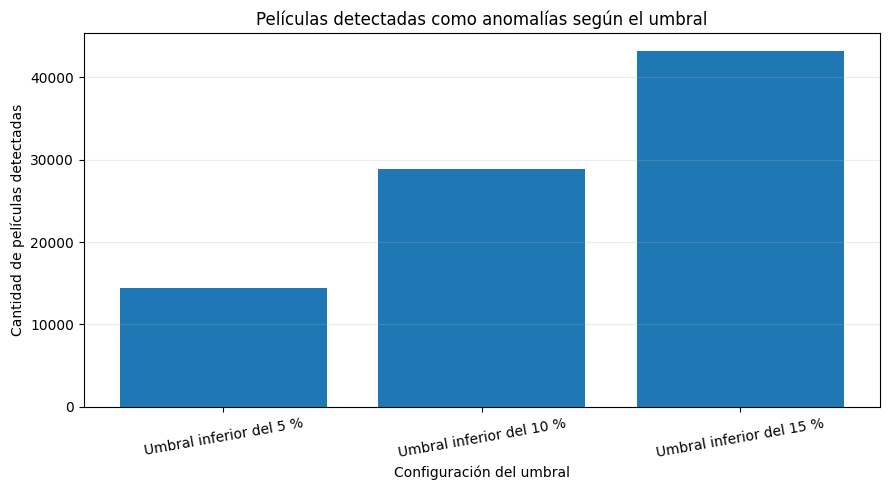

PORCENTAJE DE PELÍCULAS DETECTADAS


,configuracion,porcentaje_objetivo,porcentaje_detectado
0,Umbral inferior del 5 %,5.0,5.0
1,Umbral inferior del 10 %,10.0,10.0
2,Umbral inferior del 15 %,15.0,15.0


In [44]:
# ============================================================
# 32.5.1 VISUALIZACIÓN DE LA COMPARACIÓN
# ============================================================

plt.figure(figsize=(9, 5))
plt.bar(
    comparacion_anomalias["configuracion"],
    comparacion_anomalias["peliculas_detectadas"]
)
plt.title("Películas detectadas como anomalías según el umbral")
plt.xlabel("Configuración del umbral")
plt.ylabel("Cantidad de películas detectadas")
plt.xticks(rotation=10)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print("PORCENTAJE DE PELÍCULAS DETECTADAS")
display(
    comparacion_anomalias[
        ["configuracion", "porcentaje_objetivo", "porcentaje_detectado"]
    ].round(3)
)

## 32.6 Revisión de películas identificadas como atípicas

Se revisan los 15 registros con los puntajes más bajos dentro de la configuración de referencia del 10 %. Se muestran el título, género y variables principales para facilitar la inspección.

Estos registros son ejemplos para análisis, no una lista de películas que deban descartarse. Una película puede ser atípica por una combinación legítima de características: por ejemplo, una duración inusual, una popularidad muy alta o muy baja, o diferencias entre las calificaciones y los votos reportados por las dos fuentes.

In [45]:
# ============================================================
# 32.6 EJEMPLOS DE ANOMALÍAS Y REVISIÓN POR GÉNERO
# ============================================================

columnas_presentacion_anomalias = [
    columna for columna in [
        "primaryTitle", "title", "genero_principal", "averageRating",
        "vote_average", "popularity", "runtime", "vote_count",
        "score_iforest"
    ]
    if columna in df_anomalias_resultados.columns
]

anomalias_mas_atipicas = (
    df_anomalias_resultados.loc[
        df_anomalias_resultados["es_anomalia_10pct"]
    ]
    .sort_values("score_iforest", ascending=True)
    .head(15)
)

print("15 EJEMPLOS CON LOS PUNTAJES MÁS ATÍPICOS (CONFIGURACIÓN 10 %) ")
print("===============================================================")
display(anomalias_mas_atipicas[columnas_presentacion_anomalias])

# Comparación por género principal. Se muestra el porcentaje de anomalías,
# además del volumen, para evitar interpretar solo los conteos absolutos.
if "genero_principal" in df_anomalias_resultados.columns:
    resumen_anomalias_genero = df_anomalias_resultados.copy()
    resumen_anomalias_genero["genero_principal"] = (
        resumen_anomalias_genero["genero_principal"]
        .fillna("Sin información")
        .astype(str)
    )

    resumen_anomalias_genero = (
        resumen_anomalias_genero
        .groupby("genero_principal", dropna=False)
        .agg(
            total_peliculas=("es_anomalia_10pct", "size"),
            peliculas_atipicas=("es_anomalia_10pct", "sum")
        )
        .reset_index()
    )
    resumen_anomalias_genero["porcentaje_atipicas"] = (
        resumen_anomalias_genero["peliculas_atipicas"]
        / resumen_anomalias_genero["total_peliculas"] * 100
    )
    resumen_anomalias_genero = (
        resumen_anomalias_genero[
            resumen_anomalias_genero["total_peliculas"] >= 100
        ]
        .sort_values("porcentaje_atipicas", ascending=False)
    )

    print("\nPORCENTAJE DE ANOMALÍAS POR GÉNERO PRINCIPAL")
    print("(Se muestran géneros con al menos 100 películas analizadas.)")
    display(resumen_anomalias_genero.head(10).round(2))
else:
    resumen_anomalias_genero = pd.DataFrame()
    print("No se encontró genero_principal; se omite la comparación por género.")

15 EJEMPLOS CON LOS PUNTAJES MÁS ATÍPICOS (CONFIGURACIÓN 10 %) 


,primaryTitle,title,genero_principal,averageRating,vote_average,popularity,runtime,vote_count,score_iforest
207778,Coco,Coco,Family,8.4,8.222,166.578,105.0,17742.0,-0.761292
129184,The Dark Knight,The Dark Knight,Drama,9.1,8.512,130.643,152.0,30619.0,-0.747835
36723,The Godfather,The Godfather,Drama,9.2,8.707,158.448,175.0,18677.0,-0.746506
196997,Inside Out,Inside Out,Animation,8.1,7.922,107.292,95.0,19463.0,-0.744137
77151,The Lord of the Rings: The Return of the King,The Lord of the Rings: The Return of the King,Adventure,9.0,8.474,99.276,201.0,22334.0,-0.741695
61092,The Shawshank Redemption,The Shawshank Redemption,Drama,9.3,8.702,122.610,142.0,24649.0,-0.739055
70482,Fight Club,Fight Club,Drama,8.8,8.438,69.498,139.0,27238.0,-0.738716
38628,The Godfather Part II,The Godfather Part II,Drama,9.0,8.591,64.753,202.0,11293.0,-0.738515
67561,Shrek,Shrek,Animation,7.9,7.730,94.456,90.0,15765.0,-0.736629
242085,Puss in Boots: The Last Wish,Puss in Boots: The Last Wish,Animation,7.9,8.266,221.490,103.0,6394.0,-0.736595



PORCENTAJE DE ANOMALÍAS POR GÉNERO PRINCIPAL
(Se muestran géneros con al menos 100 películas analizadas.)


,genero_principal,total_peliculas,peliculas_atipicas,porcentaje_atipicas
20,Sin información,2778,1280,46.08
3,Animation,3630,1186,32.67
19,Science Fiction,2798,657,23.48
0,Action,20514,4250,20.72
10,Fantasy,2556,510,19.95
2,Adventure,7381,1315,17.82
12,Horror,16006,2282,14.26
24,Thriller,10200,1255,12.30
9,Family,4158,508,12.22
15,Mystery,2770,333,12.02


## 32.7 Limitaciones y riesgos de la técnica

1. **Una anomalía no es necesariamente un error.** El algoritmo identifica combinaciones poco frecuentes; no determina si una película es exitosa, rentable o de mala calidad.
2. **El umbral cambia el resultado.** Las configuraciones del 5 %, 10 % y 15 % producen distintos volúmenes de casos. No existe un porcentaje universalmente correcto; debe elegirse según el propósito del análisis y validarse con conocimiento del negocio.
3. **No existe una etiqueta real de anomalía.** Como el método es no supervisado, no se dispone de una verdad de referencia para calcular exactitud, precisión o recall. La revisión de ejemplos es necesaria.
4. **Dependencia de la calidad y cobertura de las fuentes.** Los datos faltantes se imputan con la mediana y se excluyen del análisis los registros con menos de la mitad de las variables disponibles. Esto puede ocultar patrones asociados a la ausencia de información.
5. **Sesgo de popularidad y cobertura.** IMDb y TMDB no representan por igual todas las películas, épocas, países o tipos de producción. Los resultados reflejan las características de las bases consultadas.
6. **Variables de fuentes diferentes.** Las calificaciones y los votos de IMDb y TMDB tienen escalas de medición y comunidades de usuarios diferentes. Las diferencias pueden generar perfiles atípicos sin que exista un problema en los datos.
7. **No sustituye el análisis de taquilla.** El detector no utiliza `revenue` y no predice asistencia ni recaudación. Por tanto, sus resultados no deben usarse por sí solos para decidir la programación de una sala de cine.

**Riesgo para la decisión de negocio:** descartar automáticamente una película porque el algoritmo la marque como anómala podría dejar por fuera títulos de nicho o propuestas con comportamientos poco comunes que sí podrían atraer público. Las alertas deben servir para revisar casos y complementar el análisis de taquilla, género, popularidad y demanda.

In [46]:
# ============================================================
# 32.8 EXPORTACIÓN DE RESULTADOS DEL EXPERIMENTO
# ============================================================

# Se exportan la comparación de configuraciones y la tabla de películas
# analizadas con sus puntajes y banderas. Los archivos se guardan en el
# entorno actual de Colab; no se altera ningún dataset previo.

comparacion_anomalias.to_csv(
    "comparacion_deteccion_anomalias.csv",
    index=False,
    encoding="utf-8-sig"
)

df_anomalias_resultados.to_csv(
    "resultados_deteccion_anomalias.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Archivos generados:")
print("- comparacion_deteccion_anomalias.csv")
print("- resultados_deteccion_anomalias.csv")

# Síntesis calculada directamente con los resultados de esta ejecución.
configuracion_mas_amplia = comparacion_anomalias.iloc[-1]
configuracion_referencia = comparacion_anomalias.iloc[1]

print("\nSÍNTESIS DEL EXPERIMENTO")
print("========================")
print(
    f"Se analizaron {len(df_anomalias_resultados):,} películas usando "
    f"{len(columnas_modelo_anomalias)} variables numéricas."
)
print(
    f"Con el umbral del 5 % se detectaron "
    f"{int(comparacion_anomalias.iloc[0]['peliculas_detectadas']):,} películas."
)
print(
    f"Con el umbral del 10 % se detectaron "
    f"{int(configuracion_referencia['peliculas_detectadas']):,} películas."
)
print(
    f"Con el umbral del 15 % se detectaron "
    f"{int(configuracion_mas_amplia['peliculas_detectadas']):,} películas."
)
print(
    "La configuración del 10 % se utilizó como referencia para inspeccionar "
    "ejemplos. Los casos detectados requieren interpretación y no implican "
    "que la película sea un error o un fracaso comercial."
)

Archivos generados:
- comparacion_deteccion_anomalias.csv
- resultados_deteccion_anomalias.csv

SÍNTESIS DEL EXPERIMENTO
Se analizaron 288,306 películas usando 7 variables numéricas.
Con el umbral del 5 % se detectaron 14,416 películas.
Con el umbral del 10 % se detectaron 28,831 películas.
Con el umbral del 15 % se detectaron 43,246 películas.
La configuración del 10 % se utilizó como referencia para inspeccionar ejemplos. Los casos detectados requieren interpretación y no implican que la película sea un error o un fracaso comercial.


### Conclusión de la detección de anomalías

Se incorporó una técnica no supervisada de detección de anomalías mediante Isolation Forest. El experimento utiliza características numéricas relacionadas con calificaciones, popularidad, duración, géneros y participación de usuarios, y compara tres umbrales de detección (5 %, 10 % y 15 %) sobre el mismo modelo.

La comparación permite observar cómo cambia el número de películas identificadas al modificar el umbral y facilita la revisión de los casos más atípicos. Los resultados deben interpretarse como alertas para análisis adicional, no como una clasificación de éxito o fracaso en taquilla. Las limitaciones de cobertura, los valores faltantes y las diferencias entre IMDb y TMDB deben considerarse antes de usar estos hallazgos en decisiones de programación.

**La sección queda integrada al final del notebook y se ejecuta después de completar las secciones anteriores, especialmente la sección 31.**

# CHECKPOINT 2 — Sección 1 — Segmentación (Unidad 5)

En esta sección se agrupan películas con características similares para identificar perfiles que puedan apoyar el análisis de programación de Cine Éxito. Se utiliza K-Means, un algoritmo no supervisado que forma grupos a partir de la distancia entre observaciones.

**Criterios metodológicos:**
- Se parte de `peliculas_caracteristicas`, creada en la sección 31.
- Se consolidan identificadores IMDb repetidos para que una misma película no tenga un peso mayor por aparecer varias veces. Las variables numéricas se resumen mediante la mediana y las categóricas mediante la moda.
- No se utiliza `revenue` ni `budget` para formar los grupos. La segmentación describe perfiles según características de las películas, no según una respuesta comercial.
- Se evalúan varios valores de K mediante el método del codo y el coeficiente de silueta.
- Para hacer viable el cálculo de silueta, se utiliza una muestra reproducible; el modelo final se ajusta sobre todos los registros únicos elegibles.

## 1.1 Preparación de variables y consolidación de películas

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

if "peliculas_caracteristicas" not in globals():
    raise NameError("Ejecuta primero las secciones anteriores hasta la sección 31.")

columnas_segmentacion = [
    "tconst", "primaryTitle", "genero_principal", "decada_lanzamiento",
    "averageRating", "popularity", "runtime", "cantidad_generos", "votos_log"
]
faltantes_segmentacion = [
    c for c in columnas_segmentacion if c not in peliculas_caracteristicas.columns
]
if faltantes_segmentacion:
    raise KeyError("Faltan columnas para segmentación: " + ", ".join(faltantes_segmentacion))

df_segmentacion_base = peliculas_caracteristicas[columnas_segmentacion].copy()
df_segmentacion_base["tconst"] = df_segmentacion_base["tconst"].astype("string").str.strip()
df_segmentacion_base = df_segmentacion_base[
    df_segmentacion_base["tconst"].notna() & df_segmentacion_base["tconst"].ne("")
].copy()

columnas_numericas_segmentacion = [
    "averageRating", "popularity", "runtime", "cantidad_generos", "votos_log"
]
for columna in columnas_numericas_segmentacion:
    df_segmentacion_base[columna] = pd.to_numeric(
        df_segmentacion_base[columna], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

def moda_o_nulo(serie):
    valores = serie.dropna()
    if valores.empty:
        return np.nan
    modas = valores.mode()
    return modas.iloc[0] if not modas.empty else valores.iloc[0]

# Una fila por identificador IMDb. La mediana reduce el efecto de duplicados
# con valores numéricos diferentes; la moda conserva una categoría representativa.
agregaciones_segmentacion = {
    columna: "median" for columna in columnas_numericas_segmentacion
}
agregaciones_segmentacion.update({
    "primaryTitle": moda_o_nulo,
    "genero_principal": moda_o_nulo,
    "decada_lanzamiento": moda_o_nulo
})

df_segmentacion = (
    df_segmentacion_base
    .groupby("tconst", as_index=False)
    .agg(agregaciones_segmentacion)
)

# Se excluyen registros sin ninguna característica numérica observada.
mascara_info_segmentacion = (
    df_segmentacion[columnas_numericas_segmentacion].notna().sum(axis=1) >= 3
)
df_segmentacion = df_segmentacion.loc[mascara_info_segmentacion].copy()

if len(df_segmentacion) < 100:
    raise ValueError("No hay suficientes películas elegibles para realizar la segmentación.")

X_segmentacion_original = df_segmentacion[columnas_numericas_segmentacion].copy()
imputador_segmentacion = SimpleImputer(strategy="median")
escalador_segmentacion = RobustScaler()

X_segmentacion_imputado = imputador_segmentacion.fit_transform(X_segmentacion_original)
X_segmentacion = escalador_segmentacion.fit_transform(X_segmentacion_imputado)

print("PREPARACIÓN DE LA SEGMENTACIÓN")
print("==============================")
print(f"Filas originales de características: {len(peliculas_caracteristicas):,}")
print(f"Películas únicas consolidadas: {df_segmentacion['tconst'].nunique():,}")
print(f"Películas incluidas en segmentación: {len(df_segmentacion):,}")
print(f"Identificadores repetidos consolidados: {len(df_segmentacion_base) - df_segmentacion_base['tconst'].nunique():,}")
print("Variables utilizadas:", columnas_numericas_segmentacion)
print("No se utilizaron revenue ni budget.")

PREPARACIÓN DE LA SEGMENTACIÓN
Filas originales de características: 288,306
Películas únicas consolidadas: 286,888
Películas incluidas en segmentación: 286,888
Identificadores repetidos consolidados: 1,418
Variables utilizadas: ['averageRating', 'popularity', 'runtime', 'cantidad_generos', 'votos_log']
No se utilizaron revenue ni budget.


## 1.2 Selección del número de grupos: método del codo y silueta

,k,inercia_muestra,silhouette_muestra
0,2,66143.9666,0.9837
1,3,37070.4645,0.8548
2,4,27323.7322,0.6600
3,5,21124.3317,0.6595
4,6,16770.5451,0.6129


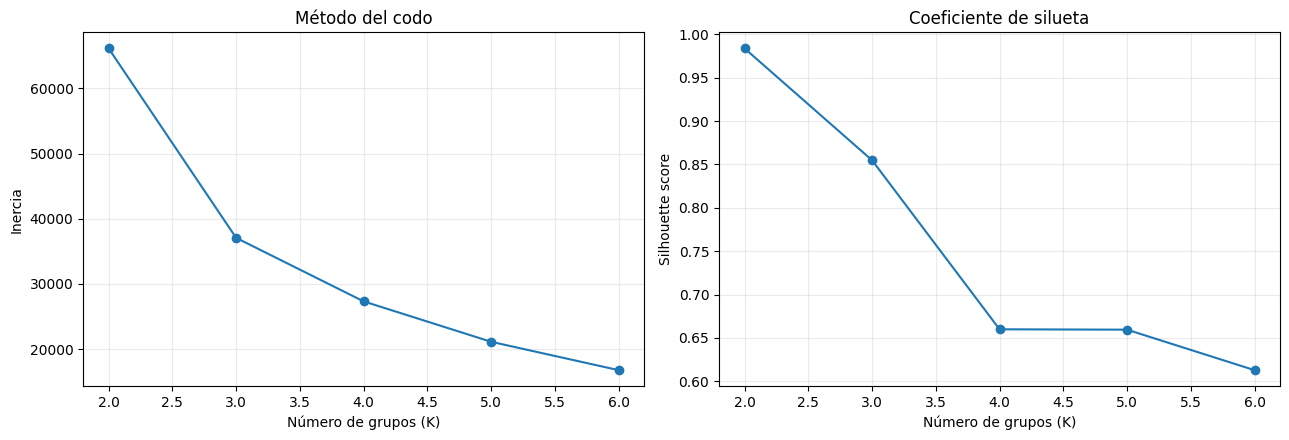

K seleccionado según el mayor coeficiente de silueta: 2
La selección se limita al rango evaluado (2 a 6 grupos); debe interpretarse junto con el gráfico del codo.


In [48]:
# Se evalúan K de 2 a 6. La silueta se calcula sobre una muestra fija
# para reducir el tiempo de ejecución y mantener la reproducibilidad.
valores_k = list(range(2, 7))
muestra_silueta_n = min(3000, len(X_segmentacion))
rng_segmentacion = np.random.RandomState(42)
indices_silueta = rng_segmentacion.choice(
    len(X_segmentacion), size=muestra_silueta_n, replace=False
)
X_muestra_silueta = X_segmentacion[indices_silueta]

resultados_k = []
for k in valores_k:
    modelo_k = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    etiquetas_muestra = modelo_k.fit_predict(X_muestra_silueta)
    inercia_muestra = modelo_k.inertia_
    silueta_muestra = silhouette_score(
        X_muestra_silueta,
        etiquetas_muestra
    )
    resultados_k.append({
        "k": k,
        "inercia_muestra": inercia_muestra,
        "silhouette_muestra": silueta_muestra
    })

evaluacion_k = pd.DataFrame(resultados_k)
display(evaluacion_k.round(4))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
ejes[0].plot(evaluacion_k["k"], evaluacion_k["inercia_muestra"], marker="o")
ejes[0].set_title("Método del codo")
ejes[0].set_xlabel("Número de grupos (K)")
ejes[0].set_ylabel("Inercia")
ejes[0].grid(alpha=0.25)

ejes[1].plot(
    evaluacion_k["k"],
    evaluacion_k["silhouette_muestra"],
    marker="o"
)
ejes[1].set_title("Coeficiente de silueta")
ejes[1].set_xlabel("Número de grupos (K)")
ejes[1].set_ylabel("Silhouette score")
ejes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Se selecciona el K con mayor silueta dentro del rango probado.
# La decisión queda respaldada por la tabla y los dos gráficos.
k_seleccionado = int(
    evaluacion_k.loc[evaluacion_k["silhouette_muestra"].idxmax(), "k"]
)
print(f"K seleccionado según el mayor coeficiente de silueta: {k_seleccionado}")
print("La selección se limita al rango evaluado (2 a 6 grupos); debe interpretarse junto con el gráfico del codo.")

## 1.3 Entrenamiento del modelo K-Means e interpretación de grupos

TAMAÑO DE LOS GRUPOS


,cantidad_peliculas,porcentaje
cluster,,
0,286872,99.99
1,16,0.01


PERFIL NUMÉRICO (MEDIANAS)


,averageRating,popularity,runtime,cantidad_generos,votos_log
cluster,,,,,
0,6.20,0.99,91.0,1.0,4.54
1,6.05,1090.19,115.0,3.0,11.55


GÉNEROS PRINCIPALES MÁS FRECUENTES POR GRUPO

Grupo 0:


,peliculas
genero_principal,
Drama,87071
Comedy,52779
Documentary,40418
Action,20275
Horror,15815



Grupo 1:


,peliculas
genero_principal,
Action,7
Horror,3
Thriller,2
Comedy,1
Animation,1


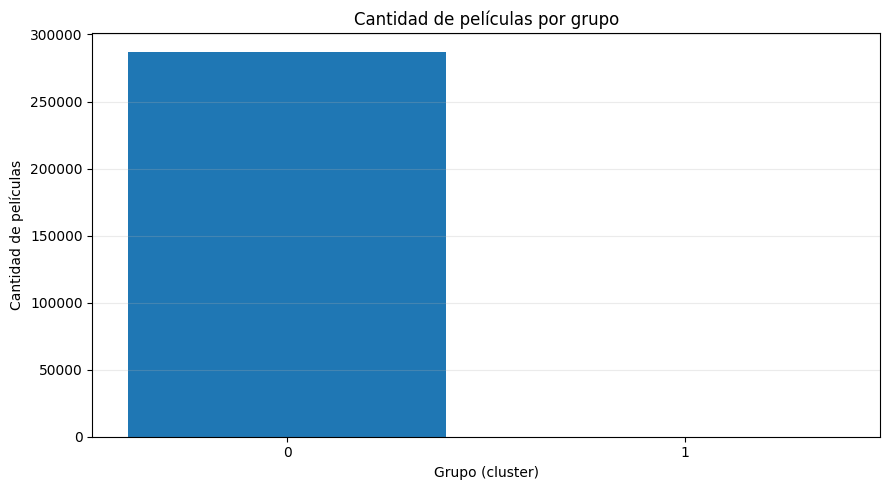

Grupo 0: 286,872 películas; mediana de calificación IMDb 6.20, popularidad 0.99, duración 91.0 minutos, géneros 1.0 y votos logarítmicos 4.54.
Grupo 1: 16 películas; mediana de calificación IMDb 6.05, popularidad 1090.19, duración 115.0 minutos, géneros 3.0 y votos logarítmicos 11.55.

La interpretación de cada grupo debe describir el perfil observado; los grupos no representan por sí mismos éxito o fracaso comercial.


In [49]:
modelo_kmeans_final = KMeans(
    n_clusters=k_seleccionado,
    random_state=42,
    n_init=10
)
df_segmentacion["cluster"] = modelo_kmeans_final.fit_predict(X_segmentacion)

# Perfil de cada grupo en las unidades originales, no en la escala transformada.
perfil_numerico_clusters = (
    df_segmentacion
    .groupby("cluster")[columnas_numericas_segmentacion]
    .median()
    .round(2)
)
tamano_clusters = (
    df_segmentacion["cluster"]
    .value_counts()
    .sort_index()
    .rename("cantidad_peliculas")
    .to_frame()
)
tamano_clusters["porcentaje"] = (
    tamano_clusters["cantidad_peliculas"] / len(df_segmentacion) * 100
).round(2)

print("TAMAÑO DE LOS GRUPOS")
display(tamano_clusters)
print("PERFIL NUMÉRICO (MEDIANAS)")
display(perfil_numerico_clusters)

if "genero_principal" in df_segmentacion.columns:
    print("GÉNEROS PRINCIPALES MÁS FRECUENTES POR GRUPO")
    for cluster_id in sorted(df_segmentacion["cluster"].unique()):
        print(f"\nGrupo {cluster_id}:")
        display(
            df_segmentacion.loc[
                df_segmentacion["cluster"] == cluster_id,
                "genero_principal"
            ].fillna("Sin información").value_counts().head(5).to_frame("peliculas")
        )

plt.figure(figsize=(9, 5))
plt.bar(
    tamano_clusters.index.astype(str),
    tamano_clusters["cantidad_peliculas"]
)
plt.title("Cantidad de películas por grupo")
plt.xlabel("Grupo (cluster)")
plt.ylabel("Cantidad de películas")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Interpretación automática orientativa basada en medianas observadas.
# La redacción final debe contrastarse con las tablas de perfil anteriores.
for cluster_id, fila in perfil_numerico_clusters.iterrows():
    print(
        f"Grupo {cluster_id}: {int(tamano_clusters.loc[cluster_id, 'cantidad_peliculas']):,} "
        f"películas; mediana de calificación IMDb {fila['averageRating']:.2f}, "
        f"popularidad {fila['popularity']:.2f}, duración {fila['runtime']:.1f} minutos, "
        f"géneros {fila['cantidad_generos']:.1f} y votos logarítmicos {fila['votos_log']:.2f}."
    )

print("\nLa interpretación de cada grupo debe describir el perfil observado; los grupos no representan por sí mismos éxito o fracaso comercial.")

### Conclusión de la Sección 1 — Segmentación

K-Means permite agrupar películas con características similares sin utilizar la recaudación para formar los grupos. El número de grupos se selecciona con base en el coeficiente de silueta dentro del rango evaluado y se contrasta con el método del codo.

Los perfiles se interpretan a partir de las medianas de calificación, popularidad, duración, cantidad de géneros y participación de votos, además de los géneros principales más frecuentes. Los grupos describen perfiles del catálogo; no deben interpretarse automáticamente como categorías de éxito comercial.

# CHECKPOINT 2 — Sección 2 — Modelo predictivo y evaluación (Unidad 6)

Se formula un problema de **clasificación binaria**: distinguir, dentro de las películas que sí tienen una recaudación positiva reportada, cuáles presentan una recaudación igual o superior a la mediana y cuáles quedan por debajo.

**Definición operacional de éxito:** `éxito_alto = 1` cuando la recaudación reportada es igual o superior a la mediana de las recaudaciones positivas observadas; `éxito_alto = 0` cuando es positiva pero inferior a esa mediana.

Esta definición permite construir una etiqueta reproducible, pero no equivale a rentabilidad: no considera presupuesto, costos de distribución, inflación, país ni número de salas. Los registros sin recaudación positiva reportada se excluyen del entrenamiento y no se etiquetan como fracasos.

Se comparan Regresión Logística y Random Forest. La variable `revenue` se utiliza exclusivamente para construir la etiqueta y nunca se incorpora a las variables predictoras.

## 2.1 Preparación de la población y definición de la variable objetivo

In [50]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

if "peliculas_caracteristicas" not in globals():
    raise NameError("No se encontró peliculas_caracteristicas. Ejecuta primero las secciones anteriores.")

columnas_modelo_requeridas = [
    "tconst", "primaryTitle", "revenue", "averageRating",
    "popularity", "runtime", "cantidad_generos", "votos_log",
    "genero_principal", "decada_lanzamiento"
]
faltantes_modelo = [
    c for c in columnas_modelo_requeridas if c not in peliculas_caracteristicas.columns
]
if faltantes_modelo:
    raise KeyError("Faltan columnas para el modelo predictivo: " + ", ".join(faltantes_modelo))

df_modelo_base = peliculas_caracteristicas[columnas_modelo_requeridas].copy()
df_modelo_base["tconst"] = df_modelo_base["tconst"].astype("string").str.strip()
df_modelo_base["revenue"] = pd.to_numeric(df_modelo_base["revenue"], errors="coerce")
df_modelo_base = df_modelo_base[
    df_modelo_base["tconst"].notna()
    & df_modelo_base["tconst"].ne("")
    & df_modelo_base["revenue"].gt(0)
].copy()

columnas_numericas_modelo = [
    "revenue", "averageRating", "popularity", "runtime",
    "cantidad_generos", "votos_log"
]
for columna in columnas_numericas_modelo:
    df_modelo_base[columna] = pd.to_numeric(
        df_modelo_base[columna], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

def moda_modelo(serie):
    valores = serie.dropna()
    if valores.empty:
        return np.nan
    modas = valores.mode()
    return modas.iloc[0] if not modas.empty else valores.iloc[0]

# Consolidar duplicados por tconst. La recaudación positiva se resume por mediana.
agregaciones_modelo = {
    "revenue": "median",
    "averageRating": "median",
    "popularity": "median",
    "runtime": "median",
    "cantidad_generos": "median",
    "votos_log": "median",
    "primaryTitle": moda_modelo,
    "genero_principal": moda_modelo,
    "decada_lanzamiento": moda_modelo
}
df_modelo = (
    df_modelo_base
    .groupby("tconst", as_index=False)
    .agg(agregaciones_modelo)
)
df_modelo = df_modelo[df_modelo["revenue"].gt(0)].copy()

if len(df_modelo) < 100:
    raise ValueError(
        "Hay menos de 100 películas únicas con recaudación positiva reportada. "
        "No es recomendable entrenar este modelo con una muestra tan pequeña."
    )

umbral_exito_alto = float(df_modelo["revenue"].median())
df_modelo["exito_alto"] = (
    df_modelo["revenue"] >= umbral_exito_alto
).astype(int)

print("DEFINICIÓN DE LA VARIABLE OBJETIVO")
print("==================================")
print(f"Películas únicas con revenue positivo reportado: {len(df_modelo):,}")
print(f"Mediana de revenue positivo (umbral de éxito alto): {umbral_exito_alto:,.2f}")
print("Distribución de la variable objetivo:")
display(
    df_modelo["exito_alto"]
    .value_counts()
    .rename(index={0: "Recaudación inferior a la mediana", 1: "Recaudación igual o superior a la mediana"})
    .to_frame("peliculas")
)
print(
    f"Cobertura frente a la tabla original de características: "
    f"{len(df_modelo) / len(peliculas_caracteristicas) * 100:.2f}%"
)
print("Los registros sin recaudación positiva reportada no se etiquetan como fracasos y no entran al modelo.")

DEFINICIÓN DE LA VARIABLE OBJETIVO
Películas únicas con revenue positivo reportado: 15,832
Mediana de revenue positivo (umbral de éxito alto): 5,000,000.00
Distribución de la variable objetivo:


,peliculas
exito_alto,
Recaudación igual o superior a la mediana,7918
Recaudación inferior a la mediana,7914


Cobertura frente a la tabla original de características: 5.49%
Los registros sin recaudación positiva reportada no se etiquetan como fracasos y no entran al modelo.


## 2.2 Variables predictoras y prevención de fuga de datos

In [51]:
columnas_numericas_predictoras = [
    "averageRating", "popularity", "runtime", "cantidad_generos", "votos_log"
]
columnas_categoricas_predictoras = [
    "genero_principal", "decada_lanzamiento"
]
columnas_predictoras = (
    columnas_numericas_predictoras + columnas_categoricas_predictoras
)

X_modelo = df_modelo[columnas_predictoras].copy()
y_modelo = df_modelo["exito_alto"].copy()

# Comprobación explícita: la recaudación y la etiqueta no pueden entrar en X.
columnas_prohibidas = {"revenue", "exito_alto", "budget"}
if columnas_prohibidas.intersection(X_modelo.columns):
    raise AssertionError("Se detectó una variable prohibida dentro de las predictoras.")

for columna in columnas_numericas_predictoras:
    X_modelo[columna] = pd.to_numeric(
        X_modelo[columna], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

for columna in columnas_categoricas_predictoras:
    X_modelo[columna] = X_modelo[columna].astype("object")
    X_modelo[columna] = X_modelo[columna].where(
        X_modelo[columna].notna(), np.nan
    )

X_train, X_test, y_train, y_test = train_test_split(
    X_modelo,
    y_modelo,
    test_size=0.20,
    random_state=42,
    stratify=y_modelo
)

def crear_onehot_modelo():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=True)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=True)

preprocesador_modelo = ColumnTransformer(
    transformers=[
        (
            "numericas",
            Pipeline(steps=[
                ("imputador", SimpleImputer(strategy="median")),
                ("escalador", RobustScaler())
            ]),
            columnas_numericas_predictoras
        ),
        (
            "categoricas",
            Pipeline(steps=[
                ("imputador", SimpleImputer(strategy="constant", fill_value="Sin información")),
                ("onehot", crear_onehot_modelo())
            ]),
            columnas_categoricas_predictoras
        )
    ],
    remainder="drop"
)

print("VARIABLES PREDICTORAS:", columnas_predictoras)
print("VARIABLES excluidas por fuga directa:", sorted(columnas_prohibidas))
print(f"Entrenamiento: {len(X_train):,} registros ({len(X_train)/len(X_modelo)*100:.1f} %)")
print(f"Prueba: {len(X_test):,} registros ({len(X_test)/len(X_modelo)*100:.1f} %)")
print("La imputación, el escalado y la codificación se ajustarán dentro de cada pipeline usando únicamente entrenamiento.")

VARIABLES PREDICTORAS: ['averageRating', 'popularity', 'runtime', 'cantidad_generos', 'votos_log', 'genero_principal', 'decada_lanzamiento']
VARIABLES excluidas por fuga directa: ['budget', 'exito_alto', 'revenue']
Entrenamiento: 12,665 registros (80.0 %)
Prueba: 3,167 registros (20.0 %)
La imputación, el escalado y la codificación se ajustarán dentro de cada pipeline usando únicamente entrenamiento.


## 2.3 Entrenamiento y comparación de modelos

,modelo,accuracy_train,accuracy_test,precision_test,recall_test,f1_test,roc_auc_test,f1_train
0,Regresión logística,0.8038,0.797,0.7878,0.8131,0.8002,0.8817,0.8059
1,Random Forest,0.8394,0.803,0.8117,0.7891,0.8003,0.8922,0.8370


Modelo seleccionado según F1 de prueba: Random Forest

Reporte de clasificación en prueba:
                                           precision    recall  f1-score   support

        Recaudación inferior a la mediana       0.79      0.82      0.81      1583
Recaudación igual o superior a la mediana       0.81      0.79      0.80      1584

                                 accuracy                           0.80      3167
                                macro avg       0.80      0.80      0.80      3167
                             weighted avg       0.80      0.80      0.80      3167



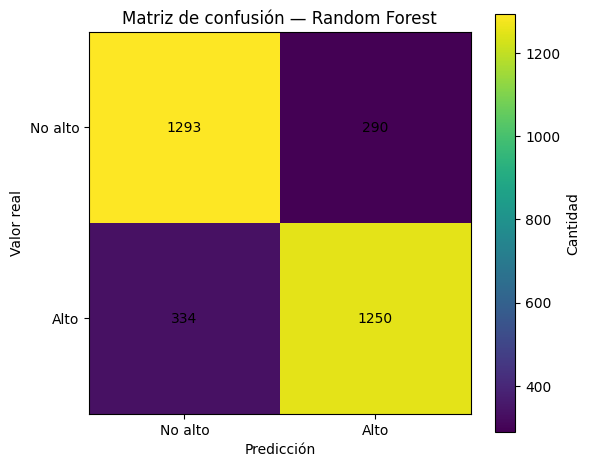

In [52]:
modelos_predictivos = {
    "Regresión logística": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
}

resultados_modelos = {}
filas_metricas_modelo = []

for nombre, estimador in modelos_predictivos.items():
    pipeline_modelo = Pipeline(steps=[
        ("preprocesador", preprocesador_modelo),
        ("modelo", estimador)
    ])
    pipeline_modelo.fit(X_train, y_train)

    pred_train = pipeline_modelo.predict(X_train)
    pred_test = pipeline_modelo.predict(X_test)

    prob_test = pipeline_modelo.predict_proba(X_test)[:, 1]
    prob_train = pipeline_modelo.predict_proba(X_train)[:, 1]

    metricas = {
        "modelo": nombre,
        "accuracy_train": accuracy_score(y_train, pred_train),
        "accuracy_test": accuracy_score(y_test, pred_test),
        "precision_test": precision_score(y_test, pred_test, zero_division=0),
        "recall_test": recall_score(y_test, pred_test, zero_division=0),
        "f1_test": f1_score(y_test, pred_test, zero_division=0),
        "roc_auc_test": roc_auc_score(y_test, prob_test),
        "f1_train": f1_score(y_train, pred_train, zero_division=0)
    }
    filas_metricas_modelo.append(metricas)
    resultados_modelos[nombre] = {
        "pipeline": pipeline_modelo,
        "pred_train": pred_train,
        "pred_test": pred_test,
        "prob_train": prob_train,
        "prob_test": prob_test
    }

comparacion_modelos = pd.DataFrame(filas_metricas_modelo)
display(comparacion_modelos.round(4))

# Se selecciona el modelo con mayor F1 en prueba; el criterio se declara antes
# de interpretar el resultado y se mantiene igual para ambos modelos.
mejor_nombre_modelo = comparacion_modelos.loc[
    comparacion_modelos["f1_test"].idxmax(), "modelo"
]
mejor_modelo = resultados_modelos[mejor_nombre_modelo]["pipeline"]
mejores_predicciones_test = resultados_modelos[mejor_nombre_modelo]["pred_test"]

print(f"Modelo seleccionado según F1 de prueba: {mejor_nombre_modelo}")
print("\nReporte de clasificación en prueba:")
print(classification_report(
    y_test,
    mejores_predicciones_test,
    target_names=["Recaudación inferior a la mediana", "Recaudación igual o superior a la mediana"],
    zero_division=0
))

matriz_confusion = confusion_matrix(y_test, mejores_predicciones_test)
plt.figure(figsize=(6, 5))
plt.imshow(matriz_confusion)
plt.title(f"Matriz de confusión — {mejor_nombre_modelo}")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks([0, 1], ["No alto", "Alto"])
plt.yticks([0, 1], ["No alto", "Alto"])
for (fila, columna), valor in np.ndenumerate(matriz_confusion):
    plt.text(columna, fila, str(valor), ha="center", va="center")
plt.colorbar(label="Cantidad")
plt.tight_layout()
plt.show()

## 2.4 Evaluación, comparación entrenamiento/prueba y riesgos de interpretación

In [53]:
# Brecha entre entrenamiento y prueba: una brecha amplia puede indicar sobreajuste.
comparacion_modelos["brecha_f1_train_test"] = (
    comparacion_modelos["f1_train"] - comparacion_modelos["f1_test"]
)
print("COMPARACIÓN DE DESEMPEÑO Y BRECHA")
display(
    comparacion_modelos[
        ["modelo", "accuracy_train", "accuracy_test", "f1_train", "f1_test", "brecha_f1_train_test"]
    ].round(4)
)

print("\nINTERPRETACIÓN AUTOMÁTICA DE LA EVALUACIÓN")
for _, fila in comparacion_modelos.iterrows():
    brecha = fila["brecha_f1_train_test"]
    if brecha > 0.15:
        observacion = "brecha amplia; revisar posible sobreajuste."
    elif brecha > 0.07:
        observacion = "brecha moderada; conviene vigilar generalización."
    else:
        observacion = "brecha reducida; no se observa una diferencia grande en F1."
    print(f"- {fila['modelo']}: {observacion}")

print("\nLIMITACIÓN TEMPORAL IMPORTANTE")
print(
    "Las variables de popularidad y votos pueden haberse medido después del estreno. "
    "Por tanto, este experimento evalúa asociaciones predictivas dentro de los datos "
    "históricos disponibles, pero no demuestra que todas las variables estuvieran "
    "disponibles antes de decidir la programación de una película."
)
print(
    "El modelo no demuestra causalidad ni rentabilidad. La etiqueta se basa en la "
    "mediana de revenue reportado y no incorpora costos, inflación, mercado ni salas."
)

COMPARACIÓN DE DESEMPEÑO Y BRECHA


,modelo,accuracy_train,accuracy_test,f1_train,f1_test,brecha_f1_train_test
0,Regresión logística,0.8038,0.797,0.8059,0.8002,0.0057
1,Random Forest,0.8394,0.803,0.8370,0.8003,0.0367



INTERPRETACIÓN AUTOMÁTICA DE LA EVALUACIÓN
- Regresión logística: brecha reducida; no se observa una diferencia grande en F1.
- Random Forest: brecha reducida; no se observa una diferencia grande en F1.

LIMITACIÓN TEMPORAL IMPORTANTE
Las variables de popularidad y votos pueden haberse medido después del estreno. Por tanto, este experimento evalúa asociaciones predictivas dentro de los datos históricos disponibles, pero no demuestra que todas las variables estuvieran disponibles antes de decidir la programación de una película.
El modelo no demuestra causalidad ni rentabilidad. La etiqueta se basa en la mediana de revenue reportado y no incorpora costos, inflación, mercado ni salas.


### Conclusión de la Sección 2 — Modelo predictivo

Se construyó un problema de clasificación binaria sobre películas únicas con recaudación positiva reportada. La etiqueta de éxito alto se define respecto a la mediana de esa recaudación observada; por ello, representa una categoría relativa dentro de la muestra disponible y no una medida de rentabilidad.

Se comparan Regresión Logística y Random Forest mediante métricas de clasificación en un conjunto de prueba separado. La recaudación se utiliza únicamente para construir la etiqueta y queda excluida de las variables predictoras. Los pasos de imputación, escalado y codificación están dentro de los pipelines, por lo que se ajustan con los datos de entrenamiento.

Los resultados deben interpretarse teniendo en cuenta la cobertura limitada de revenue y que popularidad y votos podrían corresponder a información posterior al estreno. Por tanto, el modelo es exploratorio y no debe utilizarse por sí solo para decidir la programación ni para afirmar causalidad.

# CHECKPOINT 2 — Sección 3 — Técnica complementaria elegida (Unidad 7)

**Técnica elegida: detección de anomalías mediante Isolation Forest.**

La implementación, el experimento, la comparación de configuraciones, los ejemplos y la ficha de limitaciones se encuentran en la **sección 32. Técnica complementaria: detección de anomalías**, desarrollada antes de esta sección para conservar intacto el trabajo existente.

La sección 32 compara los umbrales inferiores de 5 %, 10 % y 15 % sobre los mismos puntajes del modelo Isolation Forest. La configuración cambia el nivel de detección, no el algoritmo. Los archivos complementarios generados son `comparacion_deteccion_anomalias.csv` y `resultados_deteccion_anomalias.csv`.

**Criterio de lectura:** una anomalía es una observación con una combinación poco frecuente de características; no significa necesariamente que el registro esté equivocado, que la película sea mala o que haya fracasado en taquilla.

## Lista de verificación del Checkpoint 2

Al ejecutar el notebook completo, comprobar que:

- [ ] La Sección 1 muestra la tabla y los gráficos de codo y silueta, el K seleccionado y los perfiles de cada grupo.
- [ ] La Sección 2 muestra la distribución de la etiqueta, la separación train/test, las métricas de ambos modelos, la matriz de confusión y la comparación de desempeño entre entrenamiento y prueba.
- [ ] La Sección 2 no incorpora `revenue`, `budget` ni la etiqueta como variables predictoras.
- [ ] La Sección 3 conserva los tres umbrales de Isolation Forest, la tabla comparativa, los ejemplos y las limitaciones.
- [ ] Se ejecutaron todas las celdas desde el inicio en Google Colab y se guardaron los resultados.
- [ ] El notebook final contiene las tres secciones juntas en un único archivo.

# CHECKPOINT 3 — Integración final del proyecto Cine Éxito de Películas

## 1. Propósito del producto analítico

Este cierre integra los resultados de adquisición, calidad de datos, análisis exploratorio, ingeniería de características, segmentación, clasificación predictiva y detección de anomalías. La pregunta de negocio que orienta el proyecto es:

> ¿Qué características de las películas se asocian a un mayor éxito en taquilla, de manera que los administradores del cine puedan decidir qué títulos programar para asegurar una alta demanda?

El análisis identifica asociaciones y patrones históricos en IMDb y TMDB. **No estima directamente la asistencia de una sala de cine ni garantiza demanda futura.**

## 2. Resumen ejecutivo

Se integraron datos de IMDb y TMDB mediante los identificadores `tconst` e `imdb_id`. La tabla de análisis contiene 288.306 filas y 286.888 identificadores IMDb únicos; se detectaron 1.418 filas adicionales asociadas a identificadores repetidos, que fueron consolidadas para la segmentación y el modelo predictivo cuando correspondía.

La cobertura de recaudación es la principal restricción: solo 15.855 filas (5,50 %) tienen `revenue` positivo reportado en la tabla del EDA. Para el modelo, después de consolidar identificadores, se utilizaron 15.832 películas únicas. La mediana de recaudación positiva fue de 5.000.000 (en la unidad monetaria reportada por TMDB). Por tanto, la etiqueta “éxito alto” representa una recaudación igual o superior a esa mediana dentro de la muestra con dato positivo; no equivale a rentabilidad.

El EDA encontró una asociación de Spearman de 0,707 entre popularidad y recaudación positiva reportada, frente a 0,181 entre calificación IMDb y recaudación. Por género, Adventure presentó la mayor mediana de recaudación reportada entre las categorías comparadas (24.358.726,5), seguido de Fantasy (18.129.854) y Family (17.130.489). Estas comparaciones son descriptivas y dependen de la cobertura desigual de los datos.

La segmentación K-Means seleccionó K=2 dentro del rango probado (2 a 6), con silueta 0,9837. Sin embargo, la distribución fue extremadamente desigual: 286.872 películas (99,99 %) en el grupo 0 y 16 (0,01 %) en el grupo 1. El segundo grupo tiene medianas mucho mayores de popularidad y votos, por lo que debe interpretarse como un conjunto muy pequeño de títulos extraordinariamente visibles, no como un segmento comercial equilibrado.

En clasificación, Random Forest obtuvo F1 de prueba 0,8003 y ROC-AUC 0,8922; la Regresión Logística obtuvo F1 0,8002 y ROC-AUC 0,8817. La diferencia de F1 es mínima. Random Forest se seleccionó por el mayor F1 de prueba, pero no debe considerarse una ventaja concluyente sin validación adicional. Finalmente, Isolation Forest identificó 5 %, 10 % y 15 % de casos según los tres umbrales evaluados. Una anomalía es un perfil poco frecuente, no un error ni un fracaso de taquilla.

## 3. Hallazgos integrados

1. **La información de taquilla es limitada.** El 94,50 % de las filas del EDA no tiene recaudación positiva reportada. Cualquier conclusión sobre éxito en taquilla representa principalmente el subconjunto con información disponible.
2. **Popularidad muestra una asociación más fuerte que la calificación.** La correlación de Spearman fue 0,707 para popularidad y 0,181 para calificación IMDb frente a recaudación positiva. La asociación no demuestra causalidad y la popularidad puede medirse después del estreno.
3. **Los géneros presentan diferencias descriptivas.** Adventure tuvo la mediana más alta entre los géneros comparados con al menos 30 registros positivos; la cantidad de películas por género y la disponibilidad de revenue varían, por lo que no se debe recomendar un género únicamente con esta tabla.
4. **La segmentación detectó un grupo excepcionalmente pequeño.** La silueta alta de K=2 debe leerse junto con el tamaño 99,99 % / 0,01 %. El grupo pequeño presenta popularidad y votos muy superiores, pero su tamaño no permite tratarlo como un segmento generalizable.
5. **Los modelos clasifican la etiqueta histórica con desempeño similar.** Random Forest y Regresión Logística tuvieron F1 de prueba cercano a 0,80. Esta métrica no representa precisión de predicción de asistencia en una sala ni rentabilidad.
6. **Las anomalías sirven para priorizar revisión.** Con el umbral del 10 % se identificaron 28.831 películas. Los casos deben revisarse individualmente; no deben excluirse automáticamente.

## 4. Producto analítico: lectura conjunta

| Etapa | Resultado observado | Qué aporta a la decisión |
|---|---|---|
| Calidad y cobertura | Revenue positivo en 5,50 % de filas | Advierte que la evidencia de taquilla es incompleta |
| EDA | Spearman popularidad–revenue 0,707; rating–revenue 0,181 | Sugiere explorar visibilidad junto con otros atributos |
| Géneros | Mediana más alta: Adventure, 24,36 millones aprox. | Orienta preguntas de programación, no una regla automática |
| Segmentación | K=2; grupo minoritario de 16 títulos muy populares/votados | Ayuda a reconocer perfiles extremos del catálogo |
| Clasificación | Random Forest F1 0,8003; ROC-AUC 0,8922 | Clasifica recaudación relativa en la muestra etiquetada |
| Anomalías | 5/10/15 %: 14.416/28.831/43.246 casos | Facilita detectar registros/perfiles que merecen revisión |

## 5. Recomendaciones de uso para administradores del cine

- Utilizar los hallazgos como **insumo exploratorio** para comparar títulos y formular preguntas, no como mecanismo automático de selección.
- Revisar conjuntamente género, duración, calificaciones, popularidad y cantidad de votos, considerando la fecha en que cada dato estuvo disponible.
- Antes de tomar decisiones, contrastar los resultados con información propia del cine: asistencia histórica, preventas, capacidad de salas, horarios, ciudad, competencia, costos y derechos de exhibición. Esos datos no forman parte de este proyecto.
- No descartar películas por aparecer como anomalías ni asumir que una película con baja o ausente recaudación fracasó.
- Validar el modelo con datos temporales y externos antes de cualquier uso operativo.

## 6. Limitaciones, riesgos y consideraciones éticas

**Cobertura y representatividad.** La recaudación positiva está disponible para una fracción pequeña de la tabla. La ausencia de revenue no significa cero recaudación ni fracaso. IMDb y TMDB pueden representar de manera desigual países, épocas, idiomas, producciones independientes y películas con menor visibilidad.

**Definición de éxito.** El umbral de 5.000.000 es la mediana de recaudación positiva observada en esta muestra. No está ajustado por inflación, moneda, país, presupuesto, costos de distribución, número de salas ni periodo de exhibición. No mide utilidad o retorno de inversión.

**Variables posteriores al estreno.** Popularidad y votos pueden acumularse después del lanzamiento. Si se usan para decidir programación previa al estreno, puede existir una diferencia temporal entre la información del modelo y la disponible en el momento real de decisión.

**Duplicados y calidad.** Se detectaron identificadores repetidos y valores extremos. La consolidación por identificador se aplicó en modelado/segmentación, pero los duplicados y la calidad de las fuentes deben seguir siendo auditados. Un valor extremo puede ser real y no debe eliminarse automáticamente.

**Segmentación.** El grupo de 16 películas representa solo 0,01 % de los registros únicos. La silueta elevada puede estar influida por esa separación extrema. Conviene revisar estabilidad, características individuales y soluciones alternativas antes de atribuir significado comercial a los grupos.

**Clasificación.** El modelo se entrenó solo con películas con revenue positivo reportado. El desempeño no se extrapola a las películas sin dato. La pequeña diferencia de F1 entre modelos no prueba superioridad práctica. No se demuestra causalidad.

**Anomalías.** Isolation Forest no dispone de etiquetas reales de anomalía. Los umbrales son decisiones de sensibilidad, no niveles de error. Falsos positivos pueden marcar películas legítimas; falsos negativos pueden dejar pasar registros atípicos.

**Uso responsable.** No se debe excluir, penalizar ni negar programación a una película, distribuidor o grupo de creadores solo por una predicción, un cluster o una bandera de anomalía. Toda recomendación requiere revisión humana, contexto local y criterios transparentes.

## 7. Trazabilidad del proceso y reproducibilidad

| Unidad / etapa | Evidencia dentro del proyecto |
|---|---|
| Unidad 1 — Problema de negocio | Pregunta objetivo, hipótesis y alcance definidos en la introducción del notebook |
| Unidad 2 — Fuentes y adquisición | Descarga/carga de IMDb y TMDB, cruce por `tconst` / `imdb_id`, diccionario de datos |
| Unidad 3 — Calidad y EDA | Secciones 29 y 30: tipos, faltantes, valores extremos, estadísticas y gráficos |
| Unidad 4 — Ingeniería de características | Sección 31: variables derivadas, codificación, escalado y pipeline |
| Unidad 5 — Segmentación | Sección Checkpoint 2: K-Means, codo, silueta y perfiles |
| Unidad 6 — Modelo predictivo | Sección Checkpoint 2: train/test, Regresión Logística, Random Forest y métricas |
| Unidad 7 — Técnica complementaria | Sección 32: Isolation Forest y tres umbrales |
| Unidad 8 — Integración final | Esta sección: síntesis, producto analítico, recomendaciones y riesgos |

La reproducibilidad depende de conservar las versiones de las fuentes, las semillas aleatorias, las librerías y los archivos exportados. Las celdas originales anteriores a esta sección se mantienen sin modificación.

## 8. Conclusión general

El proyecto muestra que la popularidad histórica y ciertos atributos de las películas se asocian con diferencias en la recaudación reportada, y que es posible construir perfiles, segmentos, una clasificación exploratoria y alertas de anomalías a partir de IMDb y TMDB. Sin embargo, la cobertura limitada de taquilla, la naturaleza relativa de la etiqueta, la distribución extrema de los clusters y la posible disponibilidad posterior de algunas variables impiden convertir estos resultados en garantías de demanda o rentabilidad.

La conclusión práctica es que el análisis puede apoyar una evaluación más informada del catálogo, pero la programación de películas debe combinar estos hallazgos con datos propios del cine, validación temporal y criterio humano.


In [54]:
# 33.1 Panel de síntesis reproducible (usa resultados calculados en las secciones previas)
# Esta celda no vuelve a entrenar modelos ni modifica datasets originales.

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

filas_sintesis = [
    {"Componente": "Dataset EDA", "Indicador": "Filas", "Resultado": f"{len(df_eda):,}"},
    {"Componente": "Cobertura", "Indicador": "Revenue positivo", "Resultado": f"{df_eda['revenue'].gt(0).sum():,} filas ({df_eda['revenue'].gt(0).mean()*100:.2f} %)"},
    {"Componente": "Segmentación", "Indicador": "K seleccionado", "Resultado": str(k_seleccionado)},
    {"Componente": "Segmentación", "Indicador": "Películas grupo minoritario", "Resultado": f"{tamano_clusters['cantidad_peliculas'].min():,}"},
    {"Componente": "Modelo", "Indicador": "Modelo seleccionado", "Resultado": str(mejor_nombre_modelo)},
    {"Componente": "Modelo", "Indicador": "F1 de prueba", "Resultado": f"{comparacion_modelos.loc[comparacion_modelos['modelo'].eq(mejor_nombre_modelo), 'f1_test'].iloc[0]:.4f}"},
    {"Componente": "Anomalías", "Indicador": "Casos al 10 %", "Resultado": f"{int(comparacion_anomalias.loc[comparacion_anomalias['porcentaje_objetivo'].eq(10), 'peliculas_detectadas'].iloc[0]):,}"}
]
display(pd.DataFrame(filas_sintesis))

display(Markdown(
    "**Lectura:** estos indicadores resumen las salidas calculadas en las secciones anteriores. "
    "No constituyen una recomendación automática de programación ni una estimación directa de asistencia."
))


,Componente,Indicador,Resultado
0,Dataset EDA,Filas,"288,306"
1,Cobertura,Revenue positivo,"15,855 filas (5.50 %)"
2,Segmentación,K seleccionado,2
3,Segmentación,Películas grupo minoritario,16
4,Modelo,Modelo seleccionado,Random Forest
5,Modelo,F1 de prueba,0.8003
6,Anomalías,Casos al 10 %,"28,831"


**Lectura:** estos indicadores resumen las salidas calculadas en las secciones anteriores. No constituyen una recomendación automática de programación ni una estimación directa de asistencia.